LAB 07 — Transformer Architecture & IMDb classification
Notebook tích hợp `transformer_block.py` và `positional_encoding.py`, tự ghép encoder từ primitive PyTorch.
Chạy Restart Kernel → Run All. Cài thư viện bằng `pip install -r requirements.txt` nếu cần.

`RUN_MODE='full'`: toàn bộ dữ liệu sau làm sạch, 10 epochs/cấu hình. `quick`: subset phân tầng,
2 epochs/cấu hình để xác minh pipeline; không dùng số quick làm kết luận trên toàn IMDb.
Các kết quả, hình và checkpoint nằm riêng trong `outputs/full` hoặc `outputs/quick`.
Seed cố định không thay thế nhiều lần chạy: đây là so sánh một seed, chưa chứng minh ý nghĩa thống kê.

Luồng: dữ liệu → split → vocabulary → kiểm tra core → PE experiment → train các biến thể
→ attention diversity → LSTM → length → pooling → đánh giá test → application → error analysis → export.

In [1]:
import os
import re
import sys
import json
import time
import random
import hashlib
import platform
import zipfile
from pathlib import Path
from collections import Counter
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             ConfusionMatrixDisplay, classification_report)

RUN_MODE = os.environ.get("LAB07_MODE", "full")  # change to "quick" for a short run
assert RUN_MODE in {"quick", "full"}
LAB_DIR = Path(os.environ.get("LAB07_DIR", str(Path.cwd()))).resolve()
if not (LAB_DIR / "transformer_block.py").exists():
    LAB_DIR = Path(r"D:\Study\Study_Class\Semester_7\NLP\Lab\lab07")
DATA_PATH = Path(os.environ.get("LAB07_DATA", str(LAB_DIR.parent / "data" / "archive.zip")))
OUT = LAB_DIR / "outputs" / RUN_MODE
OUT.mkdir(parents=True, exist_ok=True)
(OUT / "checkpoints").mkdir(exist_ok=True)
sys.path.insert(0, str(LAB_DIR))
from transformer_block import TransformerBlock
from positional_encoding import PositionalEncoding

SEED = 2026
EPOCHS = 10
BATCH_SIZE = 64
D_MODEL, D_FF, N_LAYERS = 128, 256, 1
MAX_VOCAB = 8000 if RUN_MODE == "quick" else 20000
LR, DROPOUT = 1e-3, 0.1
PAD_ID, UNK_ID, CLS_ID = 0, 1, 2
BASE_LENGTH = 128
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(4)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

def sync_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

def table(frame, name):
    frame.to_csv(OUT / f"{name}.csv", index=False, encoding="utf-8-sig")
    display(frame.round(4))
    return frame

set_seed()
environment = {"mode": RUN_MODE, "seed": SEED, "epochs": EPOCHS, "batch_size": BATCH_SIZE,
               "d_model": D_MODEL, "d_ff": D_FF, "layers": N_LAYERS, "learning_rate": LR,
               "dropout": DROPOUT, "optimizer": "Adam", "device": str(DEVICE),
               "python": platform.python_version(), "torch": torch.__version__,
               "pandas": pd.__version__, "numpy": np.__version__, "sklearn": sklearn.__version__}
print(json.dumps(environment, indent=2))
print("Data:", DATA_PATH, "\nOutput:", OUT)

{
  "mode": "full",
  "seed": 2026,
  "epochs": 10,
  "batch_size": 64,
  "d_model": 128,
  "d_ff": 256,
  "layers": 1,
  "learning_rate": 0.001,
  "dropout": 0.1,
  "optimizer": "Adam",
  "device": "cpu",
  "python": "3.10.8",
  "torch": "2.1.0+cpu",
  "pandas": "2.3.3",
  "numpy": "1.26.4",
  "sklearn": "1.7.2"
}
Data: D:\Study\Study_Class\Semester_7\NLP\Lab\data\archive.zip 
Output: D:\Study\Study_Class\Semester_7\NLP\Lab\lab07\outputs\full


1. Dữ liệu, làm sạch và chia tập
Đọc CSV trực tiếp trong ZIP. Chuẩn hóa `<br>`, khoảng trắng và chữ thường để xác định trùng.
Loại cả nhóm có nhãn mâu thuẫn; loại bản trùng trước split. Split 60/20/20, seed 2026 như LAB 05.
Vocabulary chỉ học trên train. Không dùng validation/test để xây vocabulary hoặc chọn ngưỡng.
Quick lấy subset phân tầng từ từng split cố định, không chia lại các mẫu giữa các tập.

Raw=50,000; cleaned unique=49,578; removed=422; conflicts=0


,split,samples,negative,positive
0,train,29746,14817,14929
1,validation,9916,4940,4976
2,test,9916,4939,4977


,split,vocabulary,min_tokens,median_tokens,mean_tokens,p90_tokens,max_tokens,unknown_tokens_pct
0,train,20000,8,173.0,229.9690,446.0,2473,2.7358
1,validation,20000,6,175.0,233.2585,458.5,1522,2.9948
2,test,20000,10,174.0,232.8829,456.0,2146,2.9648


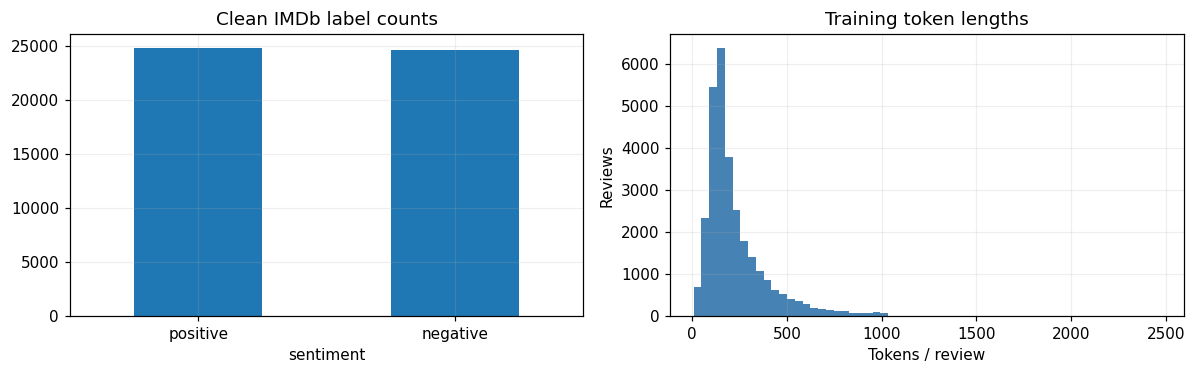

In [2]:
assert DATA_PATH.is_file(), f"Missing data: {DATA_PATH}"
with zipfile.ZipFile(DATA_PATH) as archive:
    csv_names = [name for name in archive.namelist() if name.lower().endswith(".csv")]
    assert len(csv_names) == 1, csv_names
    with archive.open(csv_names[0]) as stream:
        raw = pd.read_csv(stream)
assert {"review", "sentiment"}.issubset(raw.columns)

def clean_text(text):
    text = re.sub(r"<br\s*/?>", " ", str(text), flags=re.I)
    return re.sub(r"\s+", " ", text).strip()

TOKEN_PATTERN = re.compile(r"[a-z0-9]+(?:'[a-z0-9]+)?")

def tokenize(text):
    return TOKEN_PATTERN.findall(clean_text(text).lower())

df = raw.dropna(subset=["review", "sentiment"]).copy()
df["source_row"] = df.index
df["text"] = df.review.map(clean_text)
df["key"] = df.text.str.lower()
df = df[df.text.ne("") & df.sentiment.isin(["negative", "positive"])].copy()
conflict_keys = df.groupby("key").sentiment.nunique().loc[lambda s: s > 1].index
before = len(df)
df = df[~df.key.isin(conflict_keys)].drop_duplicates("key").reset_index(drop=True)
df["label"] = df.sentiment.map({"negative": 0, "positive": 1})
print(f"Raw={len(raw):,}; cleaned unique={len(df):,}; removed={before-len(df):,}; conflicts={len(conflict_keys)}")

train_df, rest = train_test_split(df, test_size=0.4, stratify=df.label, random_state=SEED)
valid_df, test_df = train_test_split(rest, test_size=0.5, stratify=rest.label, random_state=SEED)

def stratified_subset(frame, limit):
    if limit is None or len(frame) <= limit:
        return frame.reset_index(drop=True)
    selected, _ = train_test_split(frame, train_size=limit, stratify=frame.label, random_state=SEED)
    return selected.reset_index(drop=True)

limits = (3000, 1000, 1000) if RUN_MODE == "quick" else (None, None, None)
train_df, valid_df, test_df = [stratified_subset(f, n) for f, n in zip((train_df, valid_df, test_df), limits)]
splits = {"train": train_df, "validation": valid_df, "test": test_df}
for a, b in [(train_df, valid_df), (train_df, test_df), (valid_df, test_df)]:
    assert set(a.key).isdisjoint(b.key)
split_table = table(pd.DataFrame([
    {"split": name, "samples": len(frame), "negative": int((frame.label == 0).sum()),
     "positive": int((frame.label == 1).sum())} for name, frame in splits.items()
]), "dataset_split")
manifest = pd.concat([frame[["source_row", "label"]].assign(split=name) for name, frame in splits.items()])
manifest.to_csv(OUT / "split_manifest.csv", index=False)
counts = Counter(token for text in train_df.text for token in tokenize(text))
vocab = {"<PAD>": PAD_ID, "<UNK>": UNK_ID, "<CLS>": CLS_ID}
vocab.update({word: i + 3 for i, (word, _) in enumerate(counts.most_common(MAX_VOCAB - 3))})
(OUT / "vocab.json").write_text(json.dumps(vocab, ensure_ascii=False), encoding="utf-8")

def encode(text):
    return [vocab.get(token, UNK_ID) for token in tokenize(text)] or [UNK_ID]

encoded = {name: [encode(text) for text in frame.text] for name, frame in splits.items()}
labels = {name: frame.label.to_numpy(dtype=np.int64) for name, frame in splits.items()}
lengths = {name: np.array([len(ids) for ids in sequences]) for name, sequences in encoded.items()}
length_table = table(pd.DataFrame([
    {"split": name, "vocabulary": len(vocab), "min_tokens": lens.min(), "median_tokens": np.median(lens),
     "mean_tokens": lens.mean(), "p90_tokens": np.percentile(lens, 90), "max_tokens": lens.max(),
     "unknown_tokens_pct": 100 * sum(seq.count(UNK_ID) for seq in encoded[name]) / sum(lens)}
    for name, lens in lengths.items()
]), "dataset_lengths")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
df.sentiment.value_counts().plot.bar(ax=axes[0], rot=0, title="Clean IMDb label counts")
axes[1].hist(lengths["train"], bins=60, color="steelblue")
axes[1].set(xlabel="Tokens / review", ylabel="Reviews", title="Training token lengths")
savefig("dataset_overview.png")

2. Batch, padding và mô hình phân loại
PAD bị mask ở attention và loại khỏi mean pooling. CLS là token riêng có embedding được học,
không lấy từ đầu tiên của review làm CLS. Cả hai pooling giữ cùng số token nội dung;
CLS thêm một vị trí nên chi phí attention dùng `(max_length + 1)^2`.
LSTM dùng packed sequences để bỏ qua padding; lấy hidden state cuối của một lớp LSTM.
[PyTorch: packed sequences](https://docs.pytorch.org/docs/stable/generated/torch.nn.utils.rnn.pack_padded_sequence.html).

In [3]:
class ReviewDataset(Dataset):
    def __init__(self, split, max_length, pooling="mean"):
        self.sequences, self.labels = encoded[split], labels[split]
        self.max_length, self.pooling = max_length, pooling

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        ids = self.sequences[index][:self.max_length]
        if self.pooling == "cls":
            ids = [CLS_ID] + ids
        return torch.tensor(ids), int(self.labels[index])

def collate_batch(batch):
    sequences, y = zip(*batch)
    x = nn.utils.rnn.pad_sequence(sequences, batch_first=True, padding_value=PAD_ID)
    return x, torch.tensor(y, dtype=torch.float32)

def loader(split, spec, shuffle=False):
    return DataLoader(ReviewDataset(split, spec.max_length, spec.pooling), batch_size=BATCH_SIZE,
                      shuffle=shuffle, collate_fn=collate_batch, num_workers=0,
                      generator=torch.Generator().manual_seed(SEED))

@dataclass(frozen=True)
class Spec:
    architecture: str = "Transformer"
    heads: int = 4
    max_length: int = BASE_LENGTH
    pooling: str = "mean"
    use_pe: bool = True

class TransformerClassifier(nn.Module):
    def __init__(self, spec):
        super().__init__()
        self.spec = spec
        self.embedding = nn.Embedding(len(vocab), D_MODEL, padding_idx=PAD_ID)
        self.position = PositionalEncoding(D_MODEL, max_len=512)
        self.blocks = nn.ModuleList([
            TransformerBlock(D_MODEL, spec.heads, D_FF, dropout=DROPOUT) for _ in range(N_LAYERS)
        ])
        self.dropout = nn.Dropout(DROPOUT)
        self.classifier = nn.Linear(D_MODEL, 1)

    def forward(self, ids, return_attention=False):
        padding = ids.eq(PAD_ID)
        x = self.embedding(ids)
        if self.spec.use_pe:
            x = self.position(x)
        attention = None
        for block in self.blocks:
            if return_attention:
                x, attention = block(x, padding, return_attention=True)
            else:
                x = block(x, padding)
        if self.spec.pooling == "cls":
            pooled = x[:, 0]
        else:
            keep = (~padding).unsqueeze(-1)
            pooled = (x * keep).sum(1) / keep.sum(1).clamp_min(1)
        logits = self.classifier(self.dropout(pooled)).squeeze(-1)
        return (logits, attention) if return_attention else logits

class LSTMClassifier(nn.Module):
    def __init__(self, spec):
        super().__init__()
        self.spec = spec
        self.embedding = nn.Embedding(len(vocab), D_MODEL, padding_idx=PAD_ID)
        self.lstm = nn.LSTM(D_MODEL, D_MODEL, batch_first=True)
        self.dropout = nn.Dropout(DROPOUT)
        self.classifier = nn.Linear(D_MODEL, 1)

    def forward(self, ids):
        lens = ids.ne(PAD_ID).sum(1).cpu()
        packed = nn.utils.rnn.pack_padded_sequence(self.embedding(ids), lens, batch_first=True,
                                                  enforce_sorted=False)
        _, (hidden, _) = self.lstm(packed)
        return self.classifier(self.dropout(hidden[-1])).squeeze(-1)

def make_model(spec):
    return (LSTMClassifier(spec) if spec.architecture == "LSTM" else TransformerClassifier(spec)).to(DEVICE)

3. Kiểm tra core implementation và shape (phần 17–18)
Post-norm: `h = norm1(x + MHA(x))`, `output = norm2(h + FFN(h))`.
Không sử dụng TransformerEncoderLayer. Kiểm tra thêm PAD không ảnh hưởng logits, attention
trên PAD bằng 0, gradient hữu hạn và positional encoding hỗ trợ cả d_model lẻ.

Câu hỏi nền tảng - các phần 4, 5, 7, 13, 15 và 16

Câu hỏi: Self-attention của LAB 06 được bổ sung gì để thành Transformer block?
Trả lời: Multi-head attention, hai residual connection, hai LayerNorm và một FFN. Positional encoding được cộng vào embedding trước khi đưa vào block.

Câu hỏi: Q, K, V có vai trò gì?
Trả lời: Q biểu diễn thông tin token đang truy vấn; K dùng tính mức tương thích với Q; V là nội dung được tổng hợp theo attention weights.

Câu hỏi: Vì sao cần concatenation trước khi áp dụng W_O?
Trả lời: Ghép các kết quả heads để giữ thông tin từ từng head; W_O kết hợp thông tin giữa các heads và chiếu về chiều đầu ra mong muốn.

Câu hỏi: FFN có phải một attention mechanism khác không?
Trả lời: Không. FFN dùng Linear → ReLU → Linear để biến đổi phi tuyến từng token, với cùng bộ trọng số ở mọi vị trí; attention cho phép các token tương tác với nhau.

Câu hỏi: Chỉ dùng F(x) khác gì với x + F(x)?
Trả lời: x + F(x) giữ một đường truyền trực tiếp của đầu vào và gradient, hỗ trợ tối ưu hóa. F(x) đơn lẻ không có đường truyền trực tiếp này. Hai nhánh cần cùng shape để cộng được.

Câu hỏi: LayerNorm chuẩn hóa theo chiều nào và dùng ở đâu?
Trả lời: Theo chiều feature của từng token. Block dùng thứ tự attention → residual + LayerNorm → FFN → residual + LayerNorm để hỗ trợ training ổn định.

In [4]:
set_seed()
core = TransformerBlock(D_MODEL, 4, D_FF, dropout=0).to(DEVICE).eval()
x_demo = torch.randn(2, 7, D_MODEL, device=DEVICE)
padding_demo = torch.tensor([[False]*5+[True]*2, [False]*7], device=DEVICE)
z_demo, a_demo = core(x_demo, padding_demo, return_attention=True)
assert z_demo.shape == x_demo.shape
assert torch.allclose(a_demo.sum(-1), torch.ones_like(a_demo.sum(-1)), atol=1e-6)
assert a_demo[0, :, :, 5:].abs().max().item() == 0
z_demo.square().mean().backward()
assert all(torch.isfinite(p.grad).all() for p in core.parameters() if p.grad is not None)
assert PositionalEncoding(7)(torch.zeros(2, 4, 7)).shape == (2, 4, 7)
probe = make_model(Spec()).eval()
with torch.no_grad():
    a = probe(torch.tensor([[3, 4, 5]], device=DEVICE))
    b = probe(torch.tensor([[3, 4, 5, 0, 0]], device=DEVICE))
assert torch.allclose(a, b, atol=1e-6), (a, b)
shape_table = table(pd.DataFrame([
    {"stage": "Input / projected Q K V", "shape": "(B, T, d_model)"},
    {"stage": "Split Q K V", "shape": "(B, heads, T, d_model / heads)"},
    {"stage": "Scores / attention weights", "shape": "(B, heads, T, T)"},
    {"stage": "Per-head context", "shape": "(B, heads, T, d_model / heads)"},
    {"stage": "Merged attention / norm1", "shape": "(B, T, d_model)"},
    {"stage": "FFN hidden", "shape": "(B, T, d_ff)"},
    {"stage": "FFN output / norm2", "shape": "(B, T, d_model)"}
]), "shape_checks")
print("PASS: shape, gradient, padding invariance, masked attention, odd-dimension PE")
del core, probe, x_demo, z_demo, a_demo

,stage,shape
0,Input / projected Q K V,"(B, T, d_model)"
1,Split Q K V,"(B, heads, T, d_model / heads)"
2,Scores / attention weights,"(B, heads, T, T)"
3,Per-head context,"(B, heads, T, d_model / heads)"
4,Merged attention / norm1,"(B, T, d_model)"
5,FFN hidden,"(B, T, d_ff)"
6,FFN output / norm2,"(B, T, d_model)"


PASS: shape, gradient, padding invariance, masked attention, odd-dimension PE


18. Câu hỏi và kiểm tra shape

Câu hỏi: Với B=8, T=100, d_model=128 và 4 heads, shape thay đổi thế nào?
Trả lời: Input (8,100,128); Q/K/V trước tách heads (8,100,128); sau tách (8,4,100,32); scores (8,4,100,100); context từng head (8,4,100,32); ghép heads (8,100,128); FFN hidden (8,100,256); output (8,100,128).

Câu hỏi: Vì sao attention matrix có kích thước T × T?
Trả lời: Mỗi trong T query được so sánh với T key, tạo T² mức tương thích cho mỗi head và mỗi mẫu.

11. Experiment 1 — Positional encoding & permutation experiment (phần 12)
Hai câu có cùng token được đưa qua cùng một block với cùng trọng số, eval mode.
Không PE: output equivariant theo hoán vị; sau căn chỉnh lại token, representation khớp nhau.
Mean pooling bất biến với hoán vị khi không PE. Có PE phá vỡ ràng buộc đó nhưng một model
ngẫu nhiên có representation khác nhau chưa chứng minh đã học ngữ nghĩa hoặc đạt accuracy cao.

8. Prediction trước experiment - lưu lại dự đoán đã nêu trong trao đổi trước

Bảng dưới đây giữ lại nội dung prediction đã thảo luận trước; không thay đổi dự đoán theo kết quả hiện tại. Confidence là mức tự đánh giá trong bản dự đoán mẫu.

| Prediction | Câu hỏi | Dự đoán | Reason | Confidence |
|---|---|---|---|---|
| 1 | Transformer có xử lý token song song hơn RNN không? | Có. | Self-attention tính đồng thời các vị trí; RNN phụ thuộc hidden state trước. | Cao |
| 2 | Bỏ PE thì model còn biết thứ tự token không? | Không, nếu không có nguồn thông tin vị trí khác. | Self-attention không tự biểu diễn vị trí trước-sau. | Cao |
| 3 | Không có thông tin vị trí, có phân biệt các câu cùng token nhưng khác thứ tự không? | Không khi dùng mean pooling. | Hoán vị token chỉ hoán vị representation; mean pooling vẫn như nhau. | Cao |
| 4 | Hai heads có nhất thiết học cùng pattern không? | Không. | Mỗi head có ma trận chiếu riêng, nhưng vẫn có thể học pattern tương tự. | Cao |
| 5 | Tăng heads có chắc chắn tăng accuracy không? | Không. | Hiệu quả phụ thuộc dữ liệu và huấn luyện; d_k giảm nếu d_model cố định. | Cao |
| 6 | Transformer có luôn nhanh hơn RNN trên mọi sequence length không? | Không. | Tốc độ phụ thuộc cấu hình/phần cứng; chi phí attention tăng theo T². | Cao |

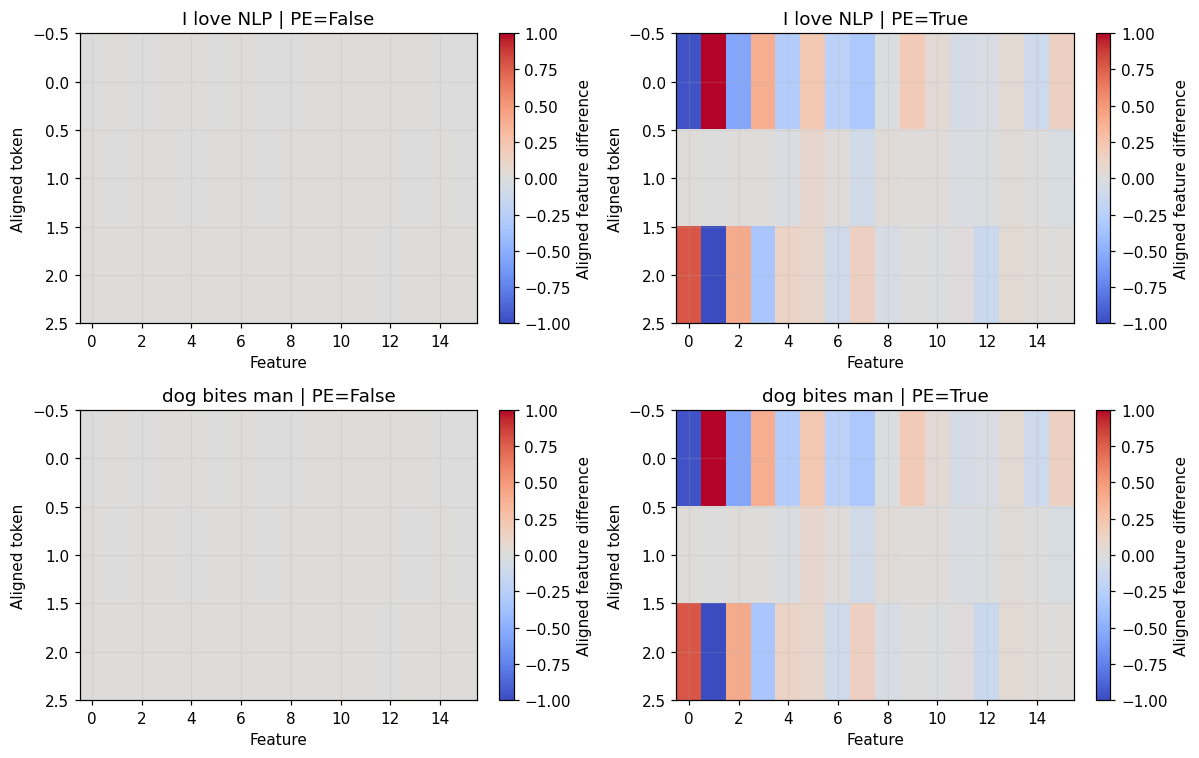

,sentence,use_pe,aligned_max_abs_difference,mean_pool_L2_distance
0,I love NLP,False,0.000,0.0000
1,I love NLP,True,1.528,0.2905
2,dog bites man,False,0.000,0.0000
3,dog bites man,True,1.528,0.2905


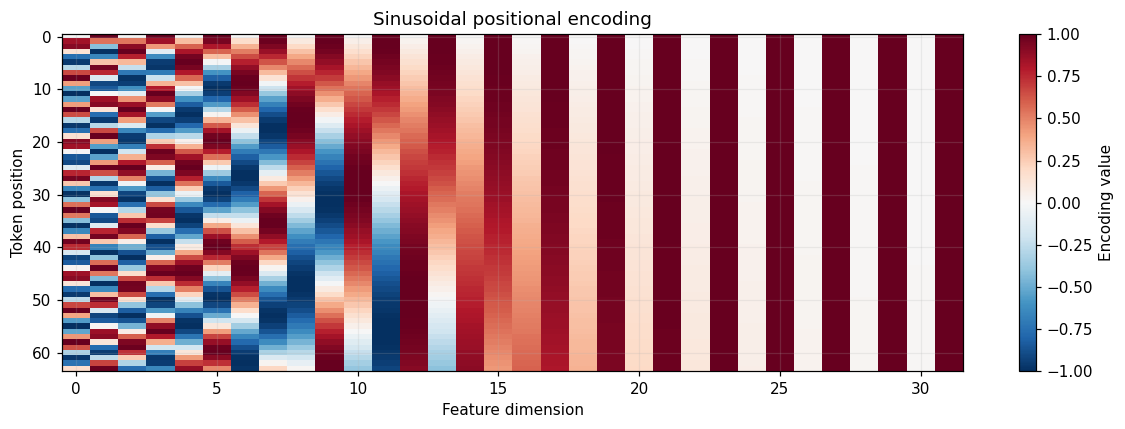

In [5]:
set_seed()
toy_pe = PositionalEncoding(16, 20)
toy_block = TransformerBlock(16, 4, 32, dropout=0).eval()
toy_embedding = nn.Embedding(3, 16)
permutation = torch.tensor([2, 1, 0])
inverse = permutation.argsort()
toy_rows = []
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for row, words in enumerate([["I", "love", "NLP"], ["dog", "bites", "man"]]):
    with torch.no_grad():
        original = toy_embedding(torch.arange(3)).unsqueeze(0)
        permuted = original[:, permutation]
        for col, use_pe in enumerate([False, True]):
            z1 = toy_block(toy_pe(original) if use_pe else original)
            z2 = toy_block(toy_pe(permuted) if use_pe else permuted)
            aligned_error = (z1 - z2[:, inverse]).abs().max().item()
            pooled_distance = torch.linalg.vector_norm(z1.mean(1) - z2.mean(1)).item()
            toy_rows.append({"sentence": " ".join(words), "use_pe": use_pe,
                             "aligned_max_abs_difference": aligned_error,
                             "mean_pool_L2_distance": pooled_distance})
            image = axes[row, col].imshow((z1-z2[:, inverse]).squeeze().numpy(), aspect="auto",
                                          cmap="coolwarm", vmin=-1, vmax=1)
            fig.colorbar(image, ax=axes[row, col], label="Aligned feature difference", fraction=0.04)
            axes[row, col].set(title=f"{' '.join(words)} | PE={use_pe}", xlabel="Feature", ylabel="Aligned token")
            if not use_pe:
                assert aligned_error < 1e-5 and pooled_distance < 1e-5
savefig("permutation_experiment.png")
pe_results = table(pd.DataFrame(toy_rows), "positional_experiment")
plt.figure(figsize=(11, 4))
plt.imshow(PositionalEncoding(32, 64).pe[0].numpy(), aspect="auto", cmap="RdBu_r")
plt.colorbar(label="Encoding value")
plt.xlabel("Feature dimension")
plt.ylabel("Token position")
plt.title("Sinusoidal positional encoding")
savefig("positional_encoding.png")

Câu hỏi và nhận xét - phần 11 và 12

Câu hỏi: Nếu chỉ dùng self-attention, không có positional information, tại sao thứ tự trở thành vấn đề?
Trả lời: Đổi thứ tự token chỉ làm hoán vị representation đầu ra. Với mean pooling, các câu cùng tập token cho representation giống nhau nên khó biểu diễn khác biệt do thứ tự.

Câu hỏi: Kết quả permutation experiment có hỗ trợ nhận định này không?
Trả lời: Có. Không PE, sai khác sau căn chỉnh và khoảng cách mean pooling đều xấp xỉ 0. Có PE, khoảng cách mean pooling là 0,2905 và sai khác lớn nhất sau căn chỉnh là 1,5280. Đây là bằng chứng representation thay đổi, chưa chứng minh model đã hiểu ngữ nghĩa hai câu.

4. Huấn luyện và đánh giá dùng chung
BCEWithLogitsLoss, Adam, clipping gradient=1. Mỗi cấu hình chạy cùng số epochs;
chọn checkpoint theo validation loss thấp nhất, ngưỡng dự đoán cố định 0.5.
Không early stopping để ngân sách epochs bằng nhau. Thời gian đo gồm train + validation
(đồng bộ CUDA), không gồm test. Cache được gắn fingerprint của dữ liệu, vocabulary, cấu hình
và source code; xóa checkpoint tương ứng hoặc đặt FORCE_RETRAIN=True để chạy lại.
Test chỉ được đánh giá sau khi đã khóa toàn bộ cấu hình, không dùng chọn mô hình.

In [6]:
FORCE_RETRAIN = False
criterion = nn.BCEWithLogitsLoss()
model_runs = {}
source_hash = hashlib.sha256(
    (LAB_DIR / "transformer_block.py").read_bytes() +
    (LAB_DIR / "positional_encoding.py").read_bytes() +
    "".join("".join(c["source"]) for c in json.loads(
        (LAB_DIR / "transformer_classification.ipynb").read_text(encoding="utf-8"))["cells"]
        if c["cell_type"] == "code").encode()
).hexdigest()
data_hash = hashlib.sha256(pd.util.hash_pandas_object(df[["key", "label"]], index=False).values.tobytes()
                           + manifest.to_csv(index=False).encode()
                           + json.dumps(vocab, sort_keys=True).encode()).hexdigest()

def compute_metrics(y, probabilities):
    pred = (np.asarray(probabilities) >= 0.5).astype(int)
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0), "f1": f1_score(y, pred, zero_division=0)}

@torch.no_grad()
def evaluate(model, batches):
    model.eval()
    total_loss, n = 0., 0
    truths, probabilities = [], []
    for ids, y in batches:
        ids, y = ids.to(DEVICE), y.to(DEVICE)
        logits = model(ids)
        total_loss += criterion(logits, y).item() * len(y)
        n += len(y)
        truths.extend(y.cpu().numpy())
        probabilities.extend(torch.sigmoid(logits).cpu().numpy())
    truth, p = np.asarray(truths, dtype=int), np.asarray(probabilities)
    return {"loss": total_loss/n, **compute_metrics(truth, p), "truth": truth, "p": p}

def train_run(spec):
    if spec in model_runs:
        return model_runs[spec]
    set_seed()
    model = make_model(spec)
    cache_config = {"spec": asdict(spec), "environment": environment,
                    "data_hash": data_hash, "source_hash": source_hash, "pipeline_version": 1}
    key = hashlib.sha256(json.dumps(cache_config, sort_keys=True).encode()).hexdigest()[:16]
    checkpoint = OUT / "checkpoints" / f"{key}.pt"
    metadata_path = checkpoint.with_suffix(".json")
    if checkpoint.exists() and metadata_path.exists() and not FORCE_RETRAIN:
        info = json.loads(metadata_path.read_text(encoding="utf-8"))
        model.load_state_dict(torch.load(checkpoint, map_location=DEVICE, weights_only=True))
        print("Loaded cache:", asdict(spec))
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=LR)
        train_loader, val_loader = loader("train", spec, True), loader("validation", spec)
        history, best_loss, best_state, best_epoch = [], float("inf"), None, 0
        if DEVICE.type == "cuda":
            torch.cuda.reset_peak_memory_stats()
        sync_device()
        started = time.perf_counter()
        for epoch in range(1, EPOCHS+1):
            model.train()
            total, count = 0., 0
            for ids, y in train_loader:
                ids, y = ids.to(DEVICE), y.to(DEVICE)
                optimizer.zero_grad(set_to_none=True)
                loss = criterion(model(ids), y)
                if not torch.isfinite(loss):
                    raise RuntimeError("Non-finite training loss")
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.)
                optimizer.step()
                total += loss.item()*len(y)
                count += len(y)
            valid = evaluate(model, val_loader)
            history.append({"epoch": epoch, "train_loss": total/count,
                            "validation_loss": valid["loss"], "validation_f1": valid["f1"]})
            if valid["loss"] < best_loss:
                best_loss, best_epoch = valid["loss"], epoch
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            print(f"{spec.architecture} h={spec.heads} L={spec.max_length} pool={spec.pooling} PE={spec.use_pe} "
                  f"epoch={epoch}/{EPOCHS} loss={total/count:.4f} val_loss={valid['loss']:.4f} val_F1={valid['f1']:.4f}", flush=True)
        sync_device()
        elapsed = time.perf_counter()-started
        peak = torch.cuda.max_memory_allocated()/2**20 if DEVICE.type == "cuda" else None
        model.load_state_dict(best_state)
        torch.save(best_state, checkpoint)
        info = {"config": cache_config, "history": history, "training_seconds": elapsed,
                "best_epoch": best_epoch, "peak_cuda_MiB": peak}
        metadata_path.write_text(json.dumps(info, indent=2), encoding="utf-8")
    valid = evaluate(model, loader("validation", spec))
    row = {**asdict(spec), "run_id": key, "parameters": sum(p.numel() for p in model.parameters()),
           "training_seconds": info["training_seconds"], "best_epoch": info["best_epoch"],
           "peak_cuda_MiB": info["peak_cuda_MiB"],
           **{f"validation_{k}": valid[k] for k in ["loss", "accuracy", "precision", "recall", "f1"]}}
    model_runs[spec] = {"model": model.cpu(), "row": row, "history": info["history"], "checkpoint": checkpoint}
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return model_runs[spec]

def run_table(specs, name):
    return table(pd.DataFrame([model_runs[spec]["row"] for spec in specs]), name)

19. Experiment 2 — Number of attention heads
Cố định d_model=128, d_ff=256, layers=1, length=128, mean pooling, PE=True.
Thử heads=1,2,4,8. Với phép chiếu dense cùng d_model, số tham số attention không tăng theo heads.
Các head chia sẻ tổng chiều biểu diễn 128; d_k giảm khi số heads tăng.

c:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.2) or chardet (7.4.3)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


Transformer h=1 L=128 pool=mean PE=True epoch=1/10 loss=0.5435 val_loss=0.4713 val_F1=0.7366
Transformer h=1 L=128 pool=mean PE=True epoch=2/10 loss=0.3750 val_loss=0.3999 val_F1=0.8355
Transformer h=1 L=128 pool=mean PE=True epoch=3/10 loss=0.3038 val_loss=0.3686 val_F1=0.8422
Transformer h=1 L=128 pool=mean PE=True epoch=4/10 loss=0.2445 val_loss=0.3836 val_F1=0.8444
Transformer h=1 L=128 pool=mean PE=True epoch=5/10 loss=0.1894 val_loss=0.4347 val_F1=0.8359
Transformer h=1 L=128 pool=mean PE=True epoch=6/10 loss=0.1424 val_loss=0.5490 val_F1=0.8152
Transformer h=1 L=128 pool=mean PE=True epoch=7/10 loss=0.1040 val_loss=0.6112 val_F1=0.8334
Transformer h=1 L=128 pool=mean PE=True epoch=8/10 loss=0.0745 val_loss=0.7462 val_F1=0.8334
Transformer h=1 L=128 pool=mean PE=True epoch=9/10 loss=0.0516 val_loss=0.8416 val_F1=0.8295
Transformer h=1 L=128 pool=mean PE=True epoch=10/10 loss=0.0338 val_loss=1.0059 val_F1=0.8252
Transformer h=2 L=128 pool=mean PE=True epoch=1/10 loss=0.5453 val_lo

,architecture,heads,max_length,pooling,use_pe,run_id,parameters,training_seconds,best_epoch,peak_cuda_MiB,validation_loss,validation_accuracy,validation_precision,validation_recall,validation_f1
0,Transformer,1,128,mean,True,aba8e619cbe37d24,2692609,845.8649,3,None,0.3686,0.8422,0.8452,0.8392,0.8422
1,Transformer,2,128,mean,True,fc4f0c0cc0bde985,2692609,1119.7700,3,None,0.3698,0.8434,0.8349,0.8575,0.8460
2,Transformer,4,128,mean,True,e5215a8ea09611d3,2692609,1419.1188,3,None,0.3746,0.8457,0.8296,0.8716,0.8501
3,Transformer,8,128,mean,True,f064db60f9c6a2c6,2692609,1621.5931,3,None,0.3821,0.8373,0.8513,0.8189,0.8348


,architecture,heads,max_length,pooling,use_pe,run_id,parameters,training_seconds,best_epoch,peak_cuda_MiB,validation_loss,validation_accuracy,validation_precision,validation_recall,validation_f1,d_k
0,Transformer,1,128,mean,True,aba8e619cbe37d24,2692609,845.8649,3,None,0.3686,0.8422,0.8452,0.8392,0.8422,128
1,Transformer,2,128,mean,True,fc4f0c0cc0bde985,2692609,1119.7700,3,None,0.3698,0.8434,0.8349,0.8575,0.8460,64
2,Transformer,4,128,mean,True,e5215a8ea09611d3,2692609,1419.1188,3,None,0.3746,0.8457,0.8296,0.8716,0.8501,32
3,Transformer,8,128,mean,True,f064db60f9c6a2c6,2692609,1621.5931,3,None,0.3821,0.8373,0.8513,0.8189,0.8348,16


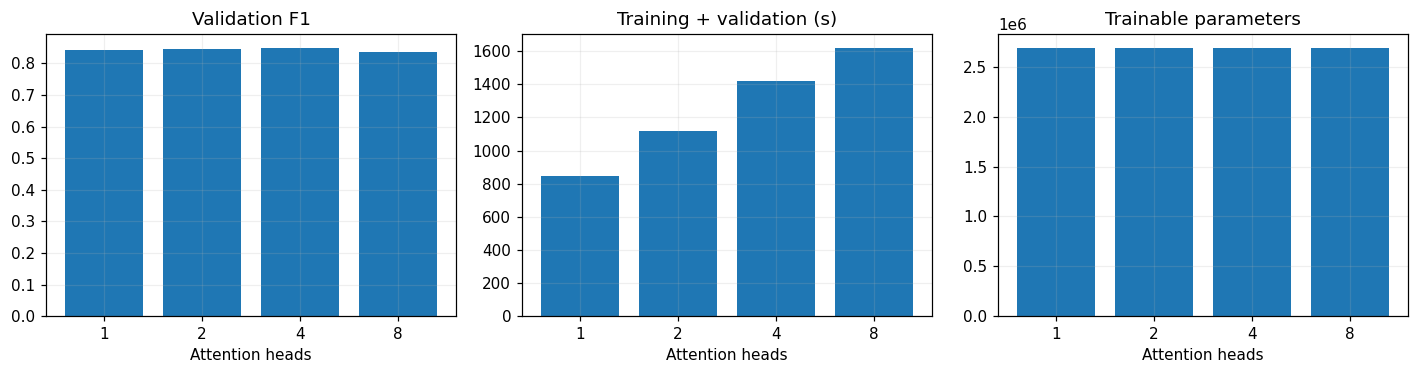

In [7]:
head_specs = [Spec(heads=h) for h in [1, 2, 4, 8]]
for spec in head_specs:
    train_run(spec)
head_results = run_table(head_specs, "heads_validation")
head_results["d_k"] = D_MODEL // head_results.heads
table(head_results, "heads_validation")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, metric, title in zip(axes, ["validation_f1", "training_seconds", "parameters"],
                            ["Validation F1", "Training + validation (s)", "Trainable parameters"]):
    ax.bar(head_results.heads.astype(str), head_results[metric])
    ax.set(title=title, xlabel="Attention heads")
savefig("attention_heads_comparison.png")
REFERENCE = Spec(heads=4)

Câu hỏi và nhận xét - phần 19

Câu hỏi: Tăng số heads có đồng nghĩa với tăng representation dimension không?
Trả lời: Không. d_model vẫn bằng 128; các heads chia nhau tổng chiều biểu diễn này. Với phép chiếu dense hiện tại, cả bốn cấu hình đều có 2.692.609 tham số.

Câu hỏi: Khi d_model cố định, tăng số heads làm d_k thay đổi thế nào?
Trả lời: d_k = d_model / n_heads. Với 1, 2, 4, 8 heads, d_k lần lượt là 128, 64, 32, 16.

Câu hỏi: Tăng heads có luôn cải thiện accuracy không?
Trả lời: Không. Test accuracy giảm từ 84.63% ở 4 heads xuống 83.90% ở 8 heads trong lần chạy này. Cần nhiều seed trước khi kết luận thứ hạng bền vững.

20. Experiment 3 — Attention head diversity
Dùng model 4 heads đã huấn luyện, eval mode (dropout tắt). Vẽ attention trên một câu đầy đủ;
hàng là query, cột là key. Đo entropy chuẩn hóa, attention đường chéo và cosine similarity
giữa ma trận các heads trên cùng câu. Những số này phụ thuộc câu, không phải quy tắc ngôn ngữ cố định.

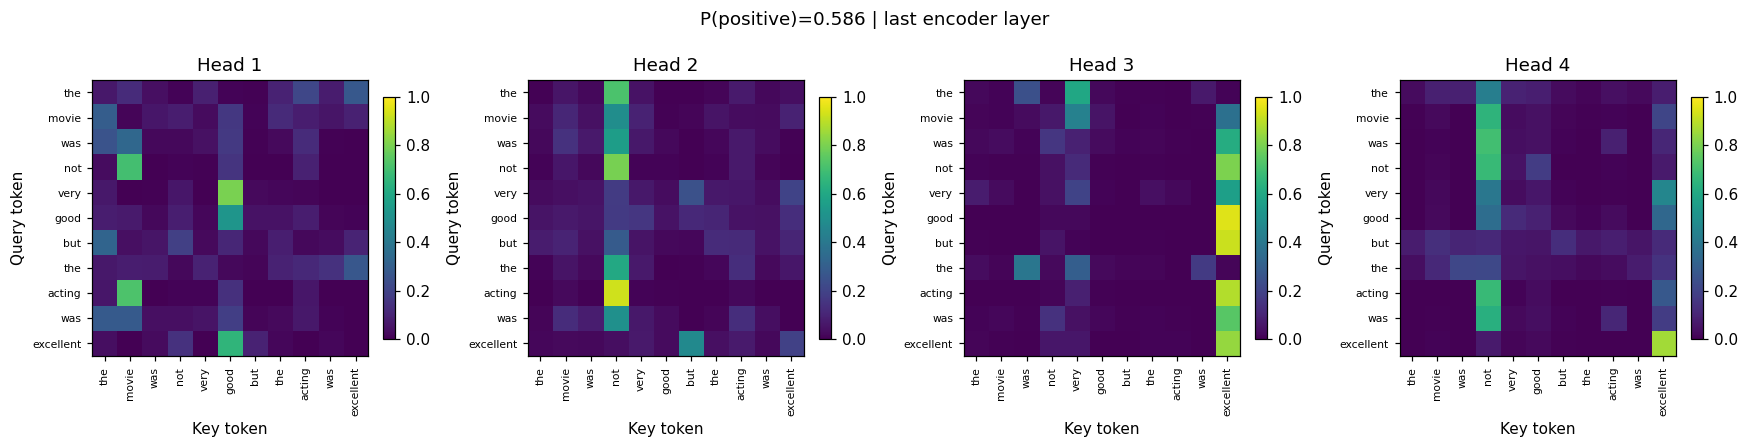

,head,normalized_entropy,mean_diagonal_mass,mean_row_max
0,1,0.6599,0.0749,0.4709
1,2,0.6441,0.1251,0.5248
2,3,0.3919,0.1040,0.7050
3,4,0.5700,0.1707,0.5260


,head_1,head_2,head_3,head_4,head
0,1.0000,0.1967,0.0934,0.1692,1
1,0.1967,1.0000,0.1994,0.7942,2
2,0.0934,0.1994,1.0000,0.4931,3
3,0.1692,0.7942,0.4931,1.0000,4


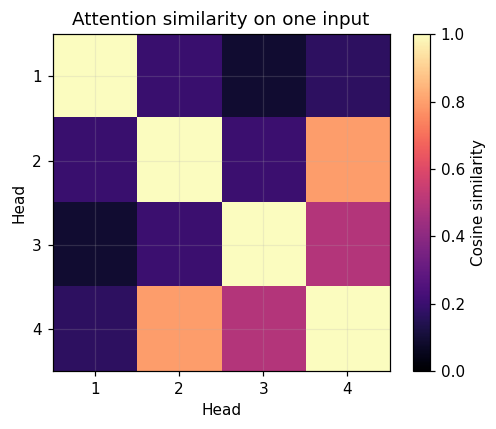

Head tập trung nhất trên câu này: **3** (entropy thấp nhất). Head phân tán nhất: **1**. Similarity cao chỉ gợi ý pattern tương tự trên đầu vào này; chưa chứng minh head dư thừa.

In [8]:
@torch.no_grad()
def attention_for_text(text, spec=REFERENCE):
    model = model_runs[spec]["model"].to(DEVICE).eval()
    tokens = tokenize(text)[:spec.max_length] or ["<UNK>"]
    ids = [vocab.get(t, UNK_ID) for t in tokens]
    if spec.pooling == "cls":
        tokens, ids = ["<CLS>"]+tokens, [CLS_ID]+ids
    logits, weights = model(torch.tensor([ids], device=DEVICE), return_attention=True)
    result = tokens, weights[0].cpu().numpy(), torch.sigmoid(logits).item()
    model.cpu()
    return result

def plot_attention(text, filename, spec=REFERENCE):
    tokens, weights, probability = attention_for_text(text, spec)
    n_heads = len(weights)
    cols = min(4, n_heads)
    rows = (n_heads+cols-1)//cols
    fig, axes = plt.subplots(rows, cols, figsize=(4*cols, 3.8*rows), squeeze=False)
    for h, ax in enumerate(axes.flat):
        if h >= n_heads:
            ax.axis("off")
            continue
        im = ax.imshow(weights[h], vmin=0, vmax=1, cmap="viridis")
        ax.set_xticks(range(len(tokens)), tokens, rotation=90, fontsize=7)
        ax.set_yticks(range(len(tokens)), tokens, fontsize=7)
        ax.set(title=f"Head {h+1}", xlabel="Key token", ylabel="Query token")
        ax.grid(False)
        fig.colorbar(im, ax=ax, fraction=0.04)
    fig.suptitle(f"P(positive)={probability:.3f} | last encoder layer", y=1.02)
    savefig(filename)
    return weights

attention_text = "The movie was not very good but the acting was excellent ."
weights = plot_attention(attention_text, "attention_heads.png")
eps = 1e-12
entropy = -(weights*np.log(weights.clip(eps))).sum(-1).mean(-1)/np.log(weights.shape[-1])
diversity_table = table(pd.DataFrame({"head": np.arange(1, len(weights)+1),
    "normalized_entropy": entropy, "mean_diagonal_mass": np.diagonal(weights, axis1=1, axis2=2).mean(1),
    "mean_row_max": weights.max(-1).mean(-1)}), "head_diversity")
flat = weights.reshape(len(weights), -1)
similarity = flat @ flat.T / (np.linalg.norm(flat, axis=1)[:, None]*np.linalg.norm(flat, axis=1)[None, :])
table(pd.DataFrame(similarity, columns=[f"head_{i+1}" for i in range(len(weights))]).assign(
    head=np.arange(1, len(weights)+1)), "head_similarity")
plt.figure(figsize=(5, 4))
plt.imshow(similarity, vmin=0, vmax=1, cmap="magma")
plt.colorbar(label="Cosine similarity")
plt.xticks(range(4), range(1, 5))
plt.yticks(range(4), range(1, 5))
plt.xlabel("Head")
plt.ylabel("Head")
plt.title("Attention similarity on one input")
savefig("head_similarity.png")
display(Markdown(f"Head tập trung nhất trên câu này: **{int(entropy.argmin()+1)}** (entropy thấp nhất). "
                 f"Head phân tán nhất: **{int(entropy.argmax()+1)}**. "
                 "Similarity cao chỉ gợi ý pattern tương tự trên đầu vào này; chưa chứng minh head dư thừa."))

Câu hỏi và nhận xét - phần 20

Câu hỏi: Các heads có tạo ra attention patterns khác nhau không?
Trả lời: Có trên câu minh họa. Entropy của heads 1-4 lần lượt là 0,6599; 0,6441; 0,3919; 0,5700. Head 3 tập trung nhất, head 1 phân tán nhất.

Câu hỏi: Các heads có giống nhau hoặc gần như redundant không?
Trả lời: Heads 2 và 4 có cosine similarity 0,7942, cho thấy một phần tương đồng. Heads 1 và 3 có similarity 0,0934, khác nhau rõ. Chưa thể kết luận head dư thừa chỉ từ một câu; cần kiểm tra nhiều đầu vào hoặc ablation từng head.

Câu hỏi: Có thể gọi một head là syntax hoặc semantics không?
Trả lời: Chưa có đủ bằng chứng để gán vai trò ngôn ngữ cố định như vậy.

21. Experiment 4 — Transformer vs LSTM
Huấn luyện lại LSTM trên đúng split/vocabulary/tokenizer/length=128 của LAB 07.
Cùng embedding dimension, batch size, optimizer, learning rate và epochs. Không lấy số từ một lần
chạy LAB 05 có length/embedding khác. Kiến trúc có số tham số và pooling khác nhau được báo rõ.

LSTM h=4 L=128 pool=last_hidden PE=False epoch=1/10 loss=0.6489 val_loss=0.6189 val_F1=0.6968
LSTM h=4 L=128 pool=last_hidden PE=False epoch=2/10 loss=0.5549 val_loss=0.5510 val_F1=0.7368
LSTM h=4 L=128 pool=last_hidden PE=False epoch=3/10 loss=0.4436 val_loss=0.4415 val_F1=0.8035
LSTM h=4 L=128 pool=last_hidden PE=False epoch=4/10 loss=0.3510 val_loss=0.4296 val_F1=0.8386
LSTM h=4 L=128 pool=last_hidden PE=False epoch=5/10 loss=0.2805 val_loss=0.4082 val_F1=0.8298
LSTM h=4 L=128 pool=last_hidden PE=False epoch=6/10 loss=0.2181 val_loss=0.4821 val_F1=0.7997
LSTM h=4 L=128 pool=last_hidden PE=False epoch=7/10 loss=0.1682 val_loss=0.4489 val_F1=0.8354
LSTM h=4 L=128 pool=last_hidden PE=False epoch=8/10 loss=0.1214 val_loss=0.5404 val_F1=0.8456
LSTM h=4 L=128 pool=last_hidden PE=False epoch=9/10 loss=0.0838 val_loss=0.5708 val_F1=0.8285
LSTM h=4 L=128 pool=last_hidden PE=False epoch=10/10 loss=0.0546 val_loss=0.6498 val_F1=0.8276


,architecture,heads,max_length,pooling,use_pe,run_id,parameters,training_seconds,best_epoch,peak_cuda_MiB,validation_loss,validation_accuracy,validation_precision,validation_recall,validation_f1
0,Transformer,4,128,mean,True,e5215a8ea09611d3,2692609,1419.1188,3,None,0.3746,0.8457,0.8296,0.8716,0.8501
1,LSTM,4,128,last_hidden,False,e2be980359b09f0e,2692225,4679.7882,5,None,0.4082,0.8311,0.8393,0.8205,0.8298


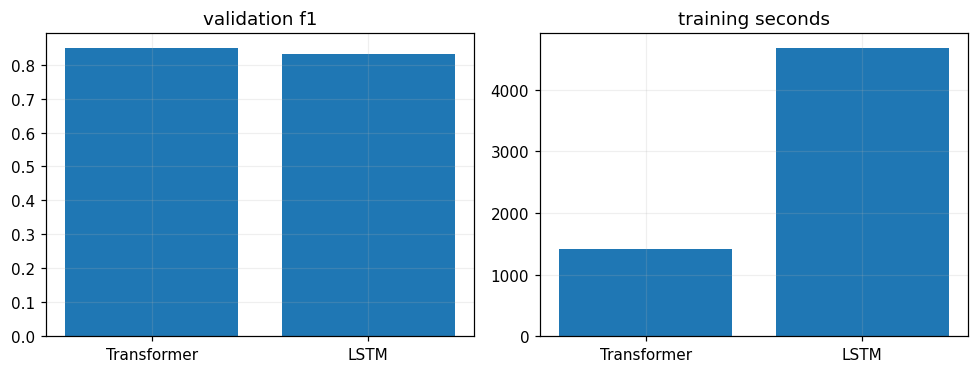

In [9]:
lstm_spec = Spec(architecture="LSTM", pooling="last_hidden", use_pe=False)
train_run(lstm_spec)
architecture_specs = [REFERENCE, lstm_spec]
architecture_results = run_table(architecture_specs, "architectures_validation")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, metric in zip(axes, ["validation_f1", "training_seconds"]):
    ax.bar(architecture_results.architecture, architecture_results[metric])
    ax.set_title(metric.replace("_", " "))
savefig("transformer_vs_lstm.png")

Câu hỏi và nhận xét - phần 21

Câu hỏi: Sự khác biệt performance có thể xuất phát từ thành phần architecture nào?
Trả lời: Transformer cho token tương tác trực tiếp qua attention, có PE, FFN và masked mean pooling; LSTM truyền thông tin qua hidden state tuần tự và lấy hidden state cuối. Pooling, cách truyền ngữ cảnh và tối ưu hóa có thể cùng ảnh hưởng; so sánh này chưa tách riêng tác động từng thành phần.

Câu hỏi: Kết quả so sánh hiện tại là gì?
Trả lời: Test F1 của Transformer là 0.8509, LSTM là 0.8316. Thời gian train + validation lần lượt là 1419.12 và 4679.79 giây. Hai model dùng cùng split, vocabulary, embedding dimension, batch size, optimizer, learning rate và 10 epochs; đây là kết quả một seed trên CPU.

22. Experiment 5 — Sequence length
Thử 32/64/128/256 token nội dung, các yếu tố khác giữ nguyên. Báo token retained và review bị cắt
trên train. `score_tensor_MiB` là dung lượng lý thuyết của một tensor scores float32 tại batch đầy,
không phải tổng RAM/VRAM của huấn luyện (còn weights, gradient, optimizer, activations).
Batch được padding động nên lượng thực tế thường thấp hơn giới hạn này; CPU peak chưa được đo.

Transformer h=4 L=32 pool=mean PE=True epoch=1/10 loss=0.6256 val_loss=0.5674 val_F1=0.7011
Transformer h=4 L=32 pool=mean PE=True epoch=2/10 loss=0.5347 val_loss=0.5343 val_F1=0.7480
Transformer h=4 L=32 pool=mean PE=True epoch=3/10 loss=0.4710 val_loss=0.5337 val_F1=0.7437
Transformer h=4 L=32 pool=mean PE=True epoch=4/10 loss=0.4105 val_loss=0.5485 val_F1=0.7441
Transformer h=4 L=32 pool=mean PE=True epoch=5/10 loss=0.3482 val_loss=0.5722 val_F1=0.7421
Transformer h=4 L=32 pool=mean PE=True epoch=6/10 loss=0.2833 val_loss=0.6503 val_F1=0.7276
Transformer h=4 L=32 pool=mean PE=True epoch=7/10 loss=0.2245 val_loss=0.8206 val_F1=0.7252
Transformer h=4 L=32 pool=mean PE=True epoch=8/10 loss=0.1729 val_loss=0.9427 val_F1=0.7223
Transformer h=4 L=32 pool=mean PE=True epoch=9/10 loss=0.1322 val_loss=1.1125 val_F1=0.7132
Transformer h=4 L=32 pool=mean PE=True epoch=10/10 loss=0.0985 val_loss=1.3663 val_F1=0.6814
Transformer h=4 L=64 pool=mean PE=True epoch=1/10 loss=0.5846 val_loss=0.5028 v

,architecture,heads,max_length,pooling,use_pe,run_id,parameters,training_seconds,best_epoch,peak_cuda_MiB,validation_loss,validation_accuracy,validation_precision,validation_recall,validation_f1,tokens_retained_pct,truncated_reviews_pct,score_elements_per_sample,score_tensor_MiB
0,Transformer,4,32,mean,True,0e581d108ff2810b,2692609,363.6470,3,None,0.5337,0.7336,0.7189,0.7703,0.7437,13.9062,99.6840,4096,1.0
1,Transformer,4,64,mean,True,29910a397c056fef,2692609,595.3116,3,None,0.4498,0.7902,0.7814,0.8081,0.7945,27.5052,94.6951,16384,4.0
2,Transformer,4,128,mean,True,e5215a8ea09611d3,2692609,1419.1188,3,None,0.3746,0.8457,0.8296,0.8716,0.8501,51.8116,73.6200,65536,16.0
3,Transformer,4,256,mean,True,fb5f137db437cf23,2692609,2738.0032,3,None,0.3132,0.8716,0.8817,0.8595,0.8705,77.3162,28.3836,262144,64.0


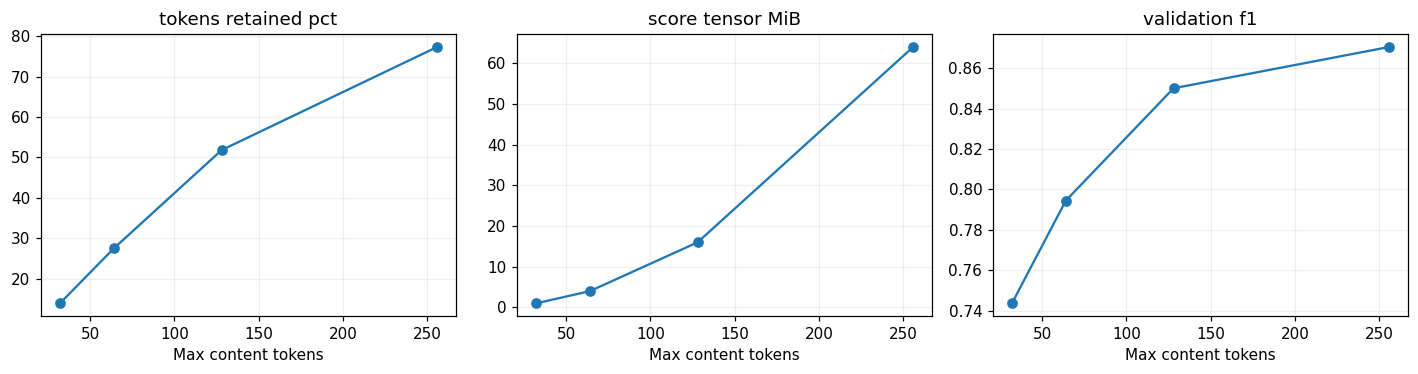

Scores grow by 4.0 when T grows 128 → 256 (fixed heads and batch).


In [10]:
length_specs = [Spec(max_length=L) for L in [32, 64, 128, 256]]
for spec in length_specs:
    train_run(spec)
length_results = pd.DataFrame([{
    **model_runs[spec]["row"],
    "tokens_retained_pct": 100*np.minimum(lengths["train"], spec.max_length).sum()/lengths["train"].sum(),
    "truncated_reviews_pct": 100*np.mean(lengths["train"] > spec.max_length),
    "score_elements_per_sample": spec.heads*spec.max_length**2,
    "score_tensor_MiB": BATCH_SIZE*spec.heads*spec.max_length**2*4/2**20
} for spec in length_specs])
table(length_results, "sequence_length_validation")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, metric in zip(axes, ["tokens_retained_pct", "score_tensor_MiB", "validation_f1"]):
    ax.plot(length_results.max_length, length_results[metric], "o-")
    ax.set(xlabel="Max content tokens", title=metric.replace("_", " "))
savefig("sequence_length.png")
print("Scores grow by", (256/128)**2, "when T grows 128 → 256 (fixed heads and batch).")

Câu hỏi và nhận xét - phần 22

Câu hỏi: Tại sao không giải quyết mọi vấn đề bằng cách tăng sequence length?
Trả lời: Tăng độ dài giúp giữ ngữ cảnh nhưng attention scores tăng theo T², tốn thêm bộ nhớ và thời gian; ngữ cảnh thêm vào cũng có thể chứa nhiễu và không bảo đảm F1 luôn tăng.

Câu hỏi: Tăng T từ 128 lên 256 thay đổi chi phí và kết quả thế nào?
Trả lời: Số scores mỗi head tăng từ 16.384 lên 65.536, tức gấp 4. Với batch 64 và 4 heads, một tensor scores float32 tăng từ 16 lên 64 MiB. Token retained trên train tăng từ 51,81% lên 77,32%; test F1 tăng từ 0,8509 lên 0,8787 trong lần chạy này. Dung lượng scores không phải tổng peak memory huấn luyện.

25. Experiment 6 — Pooling strategy
Mean pooling loại PAD; CLS pooling lấy hidden state của một token CLS riêng được train từ đầu.
Giữ cùng 128 token nội dung, CLS có 129 vị trí tổng. Vocabulary chung có sẵn CLS cho mọi cấu hình.
Không mặc định CLS tốt hơn mean pooling khi train từ đầu với dữ liệu/ngân sách nhỏ.

Transformer h=4 L=128 pool=cls PE=True epoch=1/10 loss=0.5886 val_loss=0.4964 val_F1=0.7535
Transformer h=4 L=128 pool=cls PE=True epoch=2/10 loss=0.4765 val_loss=0.4365 val_F1=0.8033
Transformer h=4 L=128 pool=cls PE=True epoch=3/10 loss=0.4077 val_loss=0.4088 val_F1=0.8025
Transformer h=4 L=128 pool=cls PE=True epoch=4/10 loss=0.3498 val_loss=0.3888 val_F1=0.8215
Transformer h=4 L=128 pool=cls PE=True epoch=5/10 loss=0.3059 val_loss=0.3923 val_F1=0.8269
Transformer h=4 L=128 pool=cls PE=True epoch=6/10 loss=0.2614 val_loss=0.4400 val_F1=0.7968
Transformer h=4 L=128 pool=cls PE=True epoch=7/10 loss=0.2293 val_loss=0.4486 val_F1=0.8255
Transformer h=4 L=128 pool=cls PE=True epoch=8/10 loss=0.2028 val_loss=0.4700 val_F1=0.8338
Transformer h=4 L=128 pool=cls PE=True epoch=9/10 loss=0.1731 val_loss=0.5170 val_F1=0.8248
Transformer h=4 L=128 pool=cls PE=True epoch=10/10 loss=0.1516 val_loss=0.5238 val_F1=0.8288


,architecture,heads,max_length,pooling,use_pe,run_id,parameters,training_seconds,best_epoch,peak_cuda_MiB,validation_loss,validation_accuracy,validation_precision,validation_recall,validation_f1
0,Transformer,4,128,mean,True,e5215a8ea09611d3,2692609,1419.1188,3,None,0.3746,0.8457,0.8296,0.8716,0.8501
1,Transformer,4,128,cls,True,c16b3d23e98b69ff,2692609,1246.1890,4,None,0.3888,0.8263,0.8484,0.7962,0.8215


,architecture,heads,max_length,pooling,use_pe,run_id,parameters,training_seconds,best_epoch,peak_cuda_MiB,validation_loss,validation_accuracy,validation_precision,validation_recall,validation_f1,total_max_positions
0,Transformer,4,128,mean,True,e5215a8ea09611d3,2692609,1419.1188,3,None,0.3746,0.8457,0.8296,0.8716,0.8501,128
1,Transformer,4,128,cls,True,c16b3d23e98b69ff,2692609,1246.1890,4,None,0.3888,0.8263,0.8484,0.7962,0.8215,129


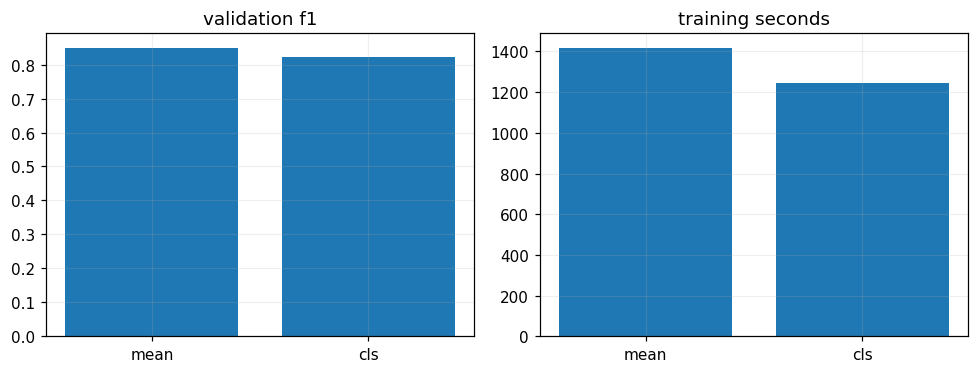

In [11]:
cls_spec = Spec(pooling="cls")
train_run(cls_spec)
pooling_specs = [REFERENCE, cls_spec]
pooling_results = run_table(pooling_specs, "pooling_validation")
pooling_results["total_max_positions"] = pooling_results.max_length + pooling_results.pooling.eq("cls").astype(int)
table(pooling_results, "pooling_validation")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, metric in zip(axes, ["validation_f1", "training_seconds"]):
    ax.bar(pooling_results.pooling, pooling_results[metric])
    ax.set_title(metric.replace("_", " "))
savefig("pooling_comparison.png")

Câu hỏi và nhận xét - phần 24 và 25

Câu hỏi: Vì sao cần pooling sau Transformer Encoder?
Trả lời: Encoder trả representation cho từng token; classification cần một vector cho cả review. Mean pooling tính trung bình các vị trí hợp lệ, loại PAD. CLS pooling lấy representation của token CLS riêng đã được học.

Câu hỏi: Cách lấy sequence representation có ảnh hưởng tới classification không?
Trả lời: Có. Mean pooling đạt test F1 0.8509, CLS pooling đạt 0.8221. Mean pooling tốt hơn trong lần chạy này; không suy ra mean luôn tốt hơn CLS với mọi dữ liệu hoặc pretrained model. CLS ở đây được học từ đầu và thêm một vị trí vào sequence.

5. Bổ sung — Ablation positional encoding trên task phân loại
Ngoài toy experiment, train một model không PE với cùng ngân sách. Mean pooling không PE
bất biến với hoán vị token đã giữ lại; phép kiểm tra shuffle thực hiện sau truncation để không
thay tập token. Đây là kiểm tra kiến trúc; F1 thấp/cao còn phụ thuộc dataset và cách train.

In [12]:
no_pe_spec = Spec(use_pe=False)
train_run(no_pe_spec)
pe_task_results = run_table([REFERENCE, no_pe_spec], "pe_ablation_validation")

Transformer h=4 L=128 pool=mean PE=False epoch=1/10 loss=0.4991 val_loss=0.4029 val_F1=0.8143
Transformer h=4 L=128 pool=mean PE=False epoch=2/10 loss=0.3500 val_loss=0.3660 val_F1=0.8391
Transformer h=4 L=128 pool=mean PE=False epoch=3/10 loss=0.2771 val_loss=0.3761 val_F1=0.8357
Transformer h=4 L=128 pool=mean PE=False epoch=4/10 loss=0.2170 val_loss=0.4313 val_F1=0.8356
Transformer h=4 L=128 pool=mean PE=False epoch=5/10 loss=0.1667 val_loss=0.4619 val_F1=0.8312
Transformer h=4 L=128 pool=mean PE=False epoch=6/10 loss=0.1204 val_loss=0.5674 val_F1=0.8265
Transformer h=4 L=128 pool=mean PE=False epoch=7/10 loss=0.0847 val_loss=0.7551 val_F1=0.8290
Transformer h=4 L=128 pool=mean PE=False epoch=8/10 loss=0.0590 val_loss=0.8132 val_F1=0.8296
Transformer h=4 L=128 pool=mean PE=False epoch=9/10 loss=0.0408 val_loss=1.0454 val_F1=0.8226
Transformer h=4 L=128 pool=mean PE=False epoch=10/10 loss=0.0313 val_loss=1.1828 val_F1=0.8171


,architecture,heads,max_length,pooling,use_pe,run_id,parameters,training_seconds,best_epoch,peak_cuda_MiB,validation_loss,validation_accuracy,validation_precision,validation_recall,validation_f1
0,Transformer,4,128,mean,True,e5215a8ea09611d3,2692609,1419.1188,3,None,0.3746,0.8457,0.8296,0.8716,0.8501
1,Transformer,4,128,mean,False,a77342c27b7ad5cd,2692609,1253.7208,2,None,0.3660,0.8379,0.8363,0.8418,0.8391


6. Đánh giá test, learning curves và confusion matrices
Tất cả cấu hình đã cố định trước bước này. Bảng test dùng để báo cáo các thực nghiệm đã định trước.
Application và error analysis dùng reference 4 heads/128 tokens/mean pooling đã chọn từ thiết kế,
không chọn model có test F1 cao nhất. Nếu tiếp tục điều chỉnh sau khi xem test, cần test độc lập mới.

,architecture,heads,max_length,pooling,use_pe,run_id,parameters,training_seconds,best_epoch,peak_cuda_MiB,validation_loss,validation_accuracy,validation_precision,validation_recall,validation_f1,test_loss,test_accuracy,test_precision,test_recall,test_f1
0,Transformer,1,128,mean,True,aba8e619cbe37d24,2692609,845.8649,3,None,0.3686,0.8422,0.8452,0.8392,0.8422,0.3628,0.8439,0.8484,0.8389,0.8436
1,Transformer,2,128,mean,True,fc4f0c0cc0bde985,2692609,1119.7700,3,None,0.3698,0.8434,0.8349,0.8575,0.8460,0.3570,0.8465,0.8397,0.8579,0.8487
2,Transformer,4,128,mean,True,e5215a8ea09611d3,2692609,1419.1188,3,None,0.3746,0.8457,0.8296,0.8716,0.8501,0.3686,0.8463,0.8293,0.8736,0.8509
3,Transformer,8,128,mean,True,f064db60f9c6a2c6,2692609,1621.5931,3,None,0.3821,0.8373,0.8513,0.8189,0.8348,0.3687,0.8390,0.8514,0.8230,0.8369
4,LSTM,4,128,last_hidden,False,e2be980359b09f0e,2692225,4679.7882,5,None,0.4082,0.8311,0.8393,0.8205,0.8298,0.4074,0.8320,0.8367,0.8266,0.8316
5,Transformer,4,32,mean,True,0e581d108ff2810b,2692609,363.6470,3,None,0.5337,0.7336,0.7189,0.7703,0.7437,0.5232,0.7439,0.7303,0.7768,0.7528
6,Transformer,4,64,mean,True,29910a397c056fef,2692609,595.3116,3,None,0.4498,0.7902,0.7814,0.8081,0.7945,0.4444,0.7944,0.7871,0.8091,0.7980
7,Transformer,4,256,mean,True,fb5f137db437cf23,2692609,2738.0032,3,None,0.3132,0.8716,0.8817,0.8595,0.8705,0.2963,0.8796,0.8886,0.8690,0.8787
8,Transformer,4,128,cls,True,c16b3d23e98b69ff,2692609,1246.1890,4,None,0.3888,0.8263,0.8484,0.7962,0.8215,0.3795,0.8256,0.8426,0.8025,0.8221
9,Transformer,4,128,mean,False,a77342c27b7ad5cd,2692609,1253.7208,2,None,0.3660,0.8379,0.8363,0.8418,0.8391,0.3577,0.8382,0.8364,0.8425,0.8394


,run_id,architecture,heads,max_length,pooling,use_pe,parameters,training_seconds,best_epoch,peak_cuda_MiB,validation_loss,validation_accuracy,validation_precision,validation_recall,validation_f1,test_loss,test_accuracy,test_precision,test_recall,test_f1
0,aba8e619cbe37d24,Transformer,1,128,mean,True,2692609,845.8649,3,None,0.3686,0.8422,0.8452,0.8392,0.8422,0.3628,0.8439,0.8484,0.8389,0.8436
1,fc4f0c0cc0bde985,Transformer,2,128,mean,True,2692609,1119.7700,3,None,0.3698,0.8434,0.8349,0.8575,0.8460,0.3570,0.8465,0.8397,0.8579,0.8487
2,e5215a8ea09611d3,Transformer,4,128,mean,True,2692609,1419.1188,3,None,0.3746,0.8457,0.8296,0.8716,0.8501,0.3686,0.8463,0.8293,0.8736,0.8509
3,f064db60f9c6a2c6,Transformer,8,128,mean,True,2692609,1621.5931,3,None,0.3821,0.8373,0.8513,0.8189,0.8348,0.3687,0.8390,0.8514,0.8230,0.8369


,run_id,architecture,heads,max_length,pooling,use_pe,parameters,training_seconds,best_epoch,peak_cuda_MiB,validation_loss,validation_accuracy,validation_precision,validation_recall,validation_f1,test_loss,test_accuracy,test_precision,test_recall,test_f1
0,e5215a8ea09611d3,Transformer,4,128,mean,True,2692609,1419.1188,3,None,0.3746,0.8457,0.8296,0.8716,0.8501,0.3686,0.8463,0.8293,0.8736,0.8509
1,e2be980359b09f0e,LSTM,4,128,last_hidden,False,2692225,4679.7882,5,None,0.4082,0.8311,0.8393,0.8205,0.8298,0.4074,0.8320,0.8367,0.8266,0.8316


,run_id,architecture,heads,max_length,pooling,use_pe,parameters,training_seconds,best_epoch,peak_cuda_MiB,validation_loss,validation_accuracy,validation_precision,validation_recall,validation_f1,test_loss,test_accuracy,test_precision,test_recall,test_f1
0,0e581d108ff2810b,Transformer,4,32,mean,True,2692609,363.6470,3,None,0.5337,0.7336,0.7189,0.7703,0.7437,0.5232,0.7439,0.7303,0.7768,0.7528
1,29910a397c056fef,Transformer,4,64,mean,True,2692609,595.3116,3,None,0.4498,0.7902,0.7814,0.8081,0.7945,0.4444,0.7944,0.7871,0.8091,0.7980
2,e5215a8ea09611d3,Transformer,4,128,mean,True,2692609,1419.1188,3,None,0.3746,0.8457,0.8296,0.8716,0.8501,0.3686,0.8463,0.8293,0.8736,0.8509
3,fb5f137db437cf23,Transformer,4,256,mean,True,2692609,2738.0032,3,None,0.3132,0.8716,0.8817,0.8595,0.8705,0.2963,0.8796,0.8886,0.8690,0.8787


,run_id,architecture,heads,max_length,pooling,use_pe,parameters,training_seconds,best_epoch,peak_cuda_MiB,validation_loss,validation_accuracy,validation_precision,validation_recall,validation_f1,test_loss,test_accuracy,test_precision,test_recall,test_f1
0,e5215a8ea09611d3,Transformer,4,128,mean,True,2692609,1419.1188,3,None,0.3746,0.8457,0.8296,0.8716,0.8501,0.3686,0.8463,0.8293,0.8736,0.8509
1,c16b3d23e98b69ff,Transformer,4,128,cls,True,2692609,1246.1890,4,None,0.3888,0.8263,0.8484,0.7962,0.8215,0.3795,0.8256,0.8426,0.8025,0.8221


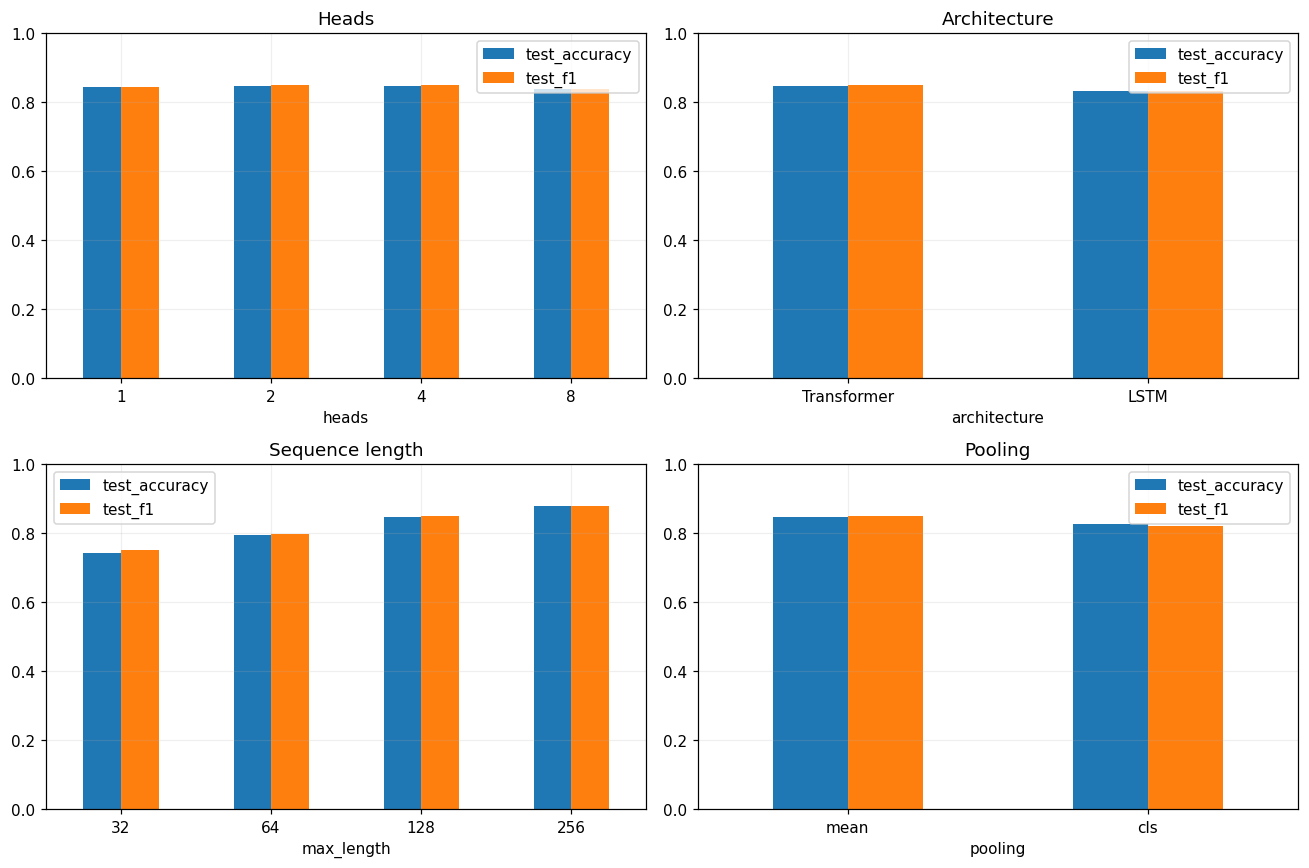

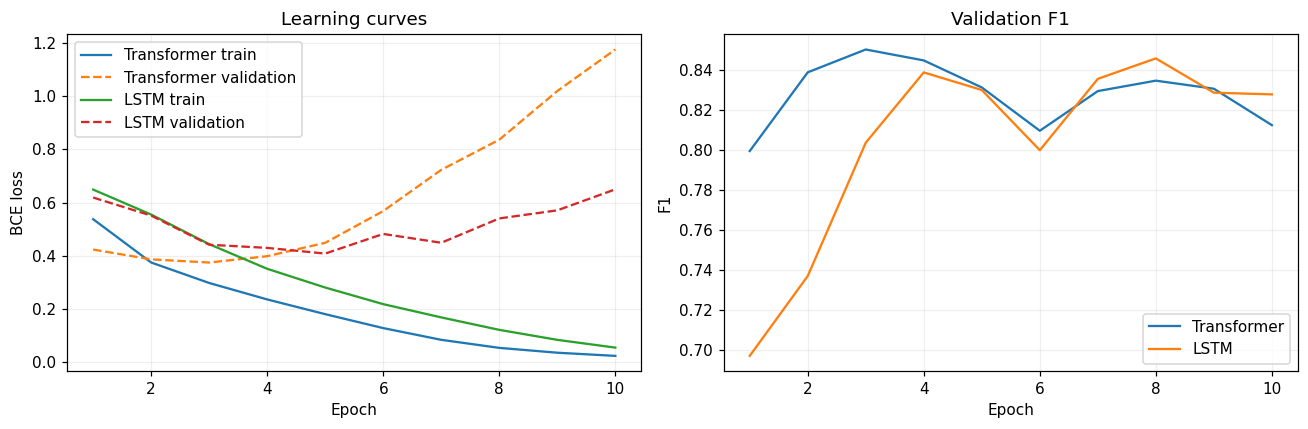

,epoch,train_loss,validation_loss,validation_f1,run_id,architecture
0,1,0.5375,0.4233,0.7993,e5215a8ea09611d3,Transformer
1,2,0.3747,0.3864,0.8386,e5215a8ea09611d3,Transformer
2,3,0.2977,0.3746,0.8501,e5215a8ea09611d3,Transformer
3,4,0.2358,0.3984,0.8446,e5215a8ea09611d3,Transformer
4,5,0.1804,0.4487,0.8311,e5215a8ea09611d3,Transformer
5,6,0.1280,0.5683,0.8094,e5215a8ea09611d3,Transformer
6,7,0.0839,0.7231,0.8293,e5215a8ea09611d3,Transformer
7,8,0.0536,0.8364,0.8345,e5215a8ea09611d3,Transformer
8,9,0.0355,1.0194,0.8304,e5215a8ea09611d3,Transformer
9,10,0.0236,1.1757,0.8122,e5215a8ea09611d3,Transformer


,epoch,train_loss,validation_loss,validation_f1,run_id
0,1,0.5435,0.4713,0.7366,aba8e619cbe37d24
1,2,0.3750,0.3999,0.8355,aba8e619cbe37d24
2,3,0.3038,0.3686,0.8422,aba8e619cbe37d24
3,4,0.2445,0.3836,0.8444,aba8e619cbe37d24
4,5,0.1894,0.4347,0.8359,aba8e619cbe37d24
...,...,...,...,...,...
95,6,0.1204,0.5674,0.8265,a77342c27b7ad5cd
96,7,0.0847,0.7551,0.8290,a77342c27b7ad5cd
97,8,0.0590,0.8132,0.8296,a77342c27b7ad5cd
98,9,0.0408,1.0454,0.8226,a77342c27b7ad5cd


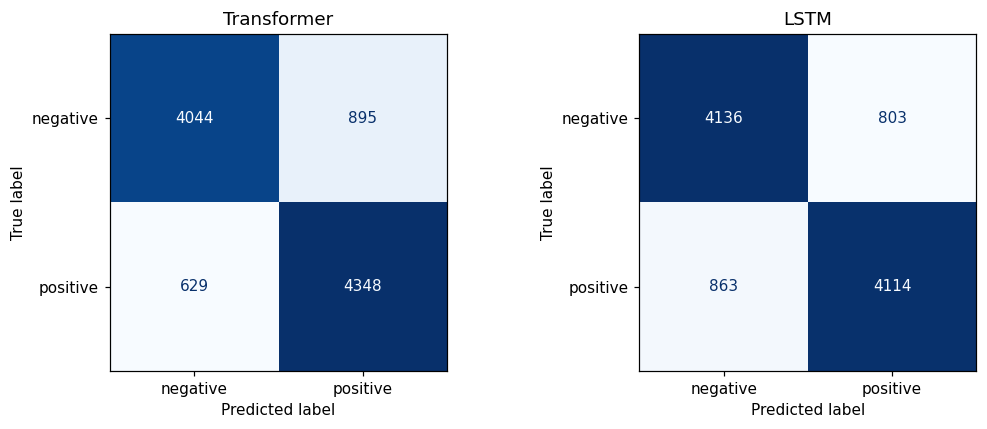

              precision    recall  f1-score   support

    negative       0.87      0.82      0.84      4939
    positive       0.83      0.87      0.85      4977

    accuracy                           0.85      9916
   macro avg       0.85      0.85      0.85      9916
weighted avg       0.85      0.85      0.85      9916



In [13]:
test_rows = []
for spec, run in model_runs.items():
    run["model"].to(DEVICE)
    result = evaluate(run["model"], loader("test", spec))
    run["test"] = result
    run["model"].cpu()
    test_rows.append({**run["row"], **{f"test_{k}": result[k] for k in ["loss", "accuracy", "precision", "recall", "f1"]}})
    pd.DataFrame({"source_row": test_df.source_row, "truth": result["truth"],
                  "p_positive": result["p"], "prediction": (result["p"] >= .5).astype(int)}).to_csv(
        OUT / f"predictions_{run['row']['run_id']}.csv", index=False)
test_results = table(pd.DataFrame(test_rows), "all_models_test")

def experiment_test(specs, filename):
    ids = [model_runs[s]["row"]["run_id"] for s in specs]
    frame = test_results.set_index("run_id").loc[ids].reset_index()
    return table(frame, filename)

heads_test = experiment_test(head_specs, "experiment2_heads_test")
architecture_test = experiment_test(architecture_specs, "experiment4_architectures_test")
length_test = experiment_test(length_specs, "experiment5_lengths_test")
pooling_test = experiment_test(pooling_specs, "experiment6_pooling_test")
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, frame, key, title in zip(axes.flat, [heads_test, architecture_test, length_test, pooling_test],
    ["heads", "architecture", "max_length", "pooling"], ["Heads", "Architecture", "Sequence length", "Pooling"]):
    frame.set_index(key)[["test_accuracy", "test_f1"]].plot.bar(ax=ax, rot=0, ylim=(0, 1), title=title)
savefig("test_comparisons.png")
history_rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for spec in architecture_specs:
    history = pd.DataFrame(model_runs[spec]["history"])
    history_rows.extend(history.assign(run_id=model_runs[spec]["row"]["run_id"], architecture=spec.architecture).to_dict("records"))
    axes[0].plot(history.epoch, history.train_loss, label=f"{spec.architecture} train")
    axes[0].plot(history.epoch, history.validation_loss, "--", label=f"{spec.architecture} validation")
    axes[1].plot(history.epoch, history.validation_f1, label=spec.architecture)
axes[0].set(xlabel="Epoch", ylabel="BCE loss", title="Learning curves")
axes[1].set(xlabel="Epoch", ylabel="F1", title="Validation F1")
for ax in axes:
    ax.legend()
savefig("learning_curves.png")
table(pd.DataFrame(history_rows), "architecture_learning_history")
all_history = pd.concat([pd.DataFrame(run["history"]).assign(run_id=run["row"]["run_id"])
                         for run in model_runs.values()], ignore_index=True)
table(all_history, "all_learning_history")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, spec in zip(axes, architecture_specs):
    result = model_runs[spec]["test"]
    ConfusionMatrixDisplay.from_predictions(result["truth"], result["p"] >= .5,
        labels=[0, 1], display_labels=["negative", "positive"], ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(spec.architecture)
    ax.grid(False)
savefig("confusion_matrix.png")
reference_test = model_runs[REFERENCE]["test"]
print(classification_report(reference_test["truth"], reference_test["p"] >= .5,
                            target_names=["negative", "positive"], zero_division=0))

,architecture,use_pe,original_f1,shuffled_f1,mean_probability_change,max_probability_change,changed_predictions_pct
0,Transformer,True,0.8509,0.8457,0.0502,0.7496,5.0121
1,Transformer,False,0.8394,0.8394,0.0000,0.0000,0.0000
2,LSTM,False,0.8316,0.8122,0.1144,0.9349,10.9823


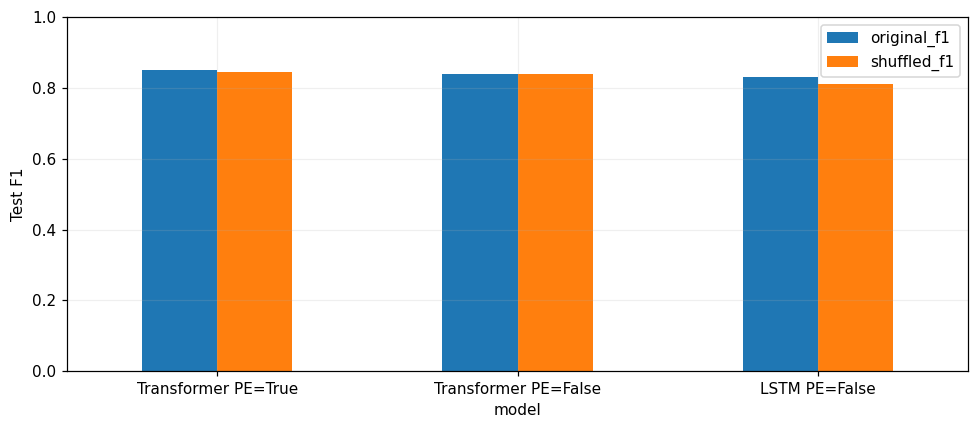

In [14]:
@torch.no_grad()
def predict_sequences(model, sequences):
    model.to(DEVICE).eval()
    probabilities = []
    for start in range(0, len(sequences), BATCH_SIZE):
        ids = nn.utils.rnn.pad_sequence([torch.tensor(seq) for seq in sequences[start:start+BATCH_SIZE]],
                                       batch_first=True, padding_value=PAD_ID).to(DEVICE)
        probabilities.extend(torch.sigmoid(model(ids)).cpu().tolist())
    model.cpu()
    return np.asarray(probabilities)

rng = np.random.default_rng(SEED)
retained = [seq[:BASE_LENGTH] for seq in encoded["test"]]
shuffled = [rng.permutation(seq).tolist() for seq in retained]
shuffle_rows = []
for spec in [REFERENCE, no_pe_spec, lstm_spec]:
    model = model_runs[spec]["model"]
    original_p = model_runs[spec]["test"]["p"]
    shuffled_p = predict_sequences(model, shuffled)
    delta = np.abs(original_p-shuffled_p)
    shuffle_rows.append({"architecture": spec.architecture, "use_pe": spec.use_pe,
                         "original_f1": compute_metrics(labels["test"], original_p)["f1"],
                         "shuffled_f1": compute_metrics(labels["test"], shuffled_p)["f1"],
                         "mean_probability_change": delta.mean(), "max_probability_change": delta.max(),
                         "changed_predictions_pct": 100*np.mean((original_p >= .5) != (shuffled_p >= .5))})
    if spec == no_pe_spec:
        assert delta.max() < 1e-5, "No-PE mean pooling should be permutation invariant in eval mode"
shuffle_results = table(pd.DataFrame(shuffle_rows), "word_order_test")
shuffle_results.assign(model=lambda f: f.architecture+" PE="+f.use_pe.astype(str)).set_index("model")[
    ["original_f1", "shuffled_f1"]].plot.bar(figsize=(9, 4), rot=0, ylim=(0, 1))
plt.ylabel("Test F1")
savefig("word_order_test.png")

Câu hỏi và nhận xét - positional ablation và word order

Câu hỏi: Model đã train có thay đổi khi đảo thứ tự token không?
Trả lời: Không PE và dùng mean pooling, F1 giữ nguyên 0,8394 và không có dự đoán nào đổi. Có PE, F1 giảm từ 0,8509 xuống 0,8457, với 5,0121% dự đoán đổi. Việc shuffle được thực hiện sau truncation để giữ nguyên tập token.

23. Application — Transformer text classification
Raw text → tokenizer → IDs → embedding → PE → encoder → masked mean pooling → classifier.
Xác suất sigmoid chưa được calibration. Nhãn ví dụ rõ ràng chỉ dùng kiểm tra định tính;
câu mơ hồ không có nhãn đúng gán sẵn. Cột truncation cho biết input đã bị cắt hay chưa.

,case,text,p_positive,prediction,total_tokens,retained_tokens,truncated,expected_for_demo
0,short,I really enjoyed this movie.,0.9992,positive,5,5,False,positive
1,negative,This was a boring and terrible movie.,0.0003,negative,7,7,False,negative
2,negation,I did not enjoy this movie at all.,0.0708,negative,8,8,False,negative
3,contrast,"The acting was good, but the story was awful a...",0.0037,negative,14,14,False,negative
4,ambiguous,The movie was strange and quite different from...,0.9901,positive,11,11,False,None
5,long,The story follows several people through an or...,0.9989,positive,327,128,True,positive


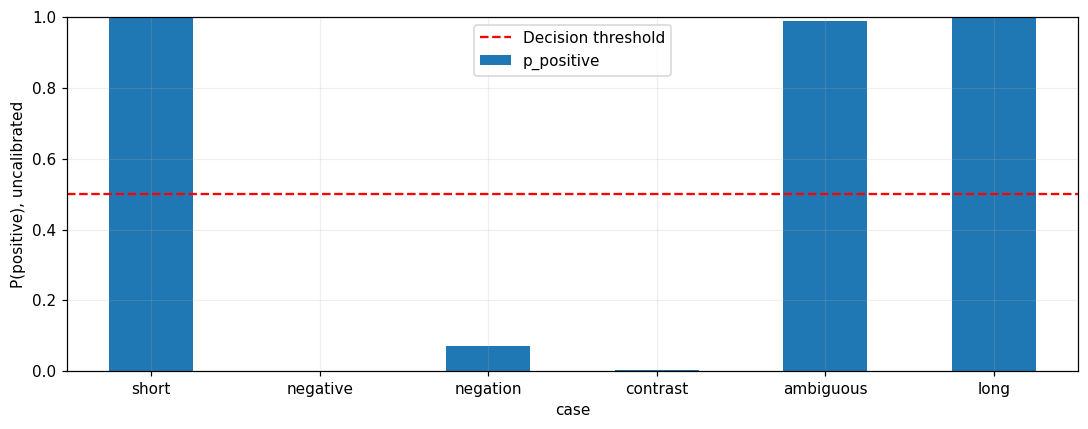

,text,p_positive,prediction,total_tokens,retained_tokens,truncated
0,"The film was not perfect, but I loved it.",0.998869,positive,9,9,False


In [15]:
def predict_texts(texts, spec=REFERENCE):
    sequences = []
    for text in texts:
        seq = encode(text)[:spec.max_length]
        sequences.append(([CLS_ID]+seq) if spec.pooling == "cls" else seq)
    p = predict_sequences(model_runs[spec]["model"], sequences)
    return pd.DataFrame({"text": texts, "p_positive": p,
                         "prediction": np.where(p >= .5, "positive", "negative"),
                         "total_tokens": [len(tokenize(t)) for t in texts],
                         "retained_tokens": [min(len(tokenize(t)), spec.max_length) for t in texts],
                         "truncated": [len(tokenize(t)) > spec.max_length for t in texts]})

application_cases = [
    ("short", "I really enjoyed this movie.", "positive"),
    ("negative", "This was a boring and terrible movie.", "negative"),
    ("negation", "I did not enjoy this movie at all.", "negative"),
    ("contrast", "The acting was good, but the story was awful and I disliked the movie.", "negative"),
    ("ambiguous", "The movie was strange and quite different from what I expected.", None),
    ("long", "The story follows several people through an ordinary day. "*35 +
     "Despite the slow start, I loved the ending and recommend the movie.", "positive")
]
application = predict_texts([case[1] for case in application_cases])
application.insert(0, "case", [case[0] for case in application_cases])
application["expected_for_demo"] = [case[2] for case in application_cases]
table(application, "application_predictions")
ax = application.plot.bar(x="case", y="p_positive", figsize=(10, 4), ylim=(0, 1), legend=False, rot=0)
ax.axhline(.5, color="red", linestyle="--", label="Decision threshold")
ax.set_ylabel("P(positive), uncalibrated")
ax.legend()
savefig("application_predictions.png")
# Use your own text, after training:
display(predict_texts(["The film was not perfect, but I loved it."]))

Câu hỏi và nhận xét - phần 23

Câu hỏi: Application đã kiểm tra đủ những loại câu nào?
Trả lời: Có câu ngắn, câu dài, phủ định, tương phản, sentiment mơ hồ và một ví dụ negative rõ ràng. Các câu có kỳ vọng rõ trong bảng demo được phân loại đúng; câu mơ hồ không được gán nhãn đúng sẵn.

Câu hỏi: Câu mơ hồ có P(positive) cao có chứng minh model hiểu đúng không?
Trả lời: Không. Câu “The movie was strange and quite different from what I expected” có P(positive)=0,9901 nhưng chưa có nhãn chuẩn. Xác suất sigmoid chưa calibration không phải bằng chứng về độ chắc chắn đáng tin cậy.

Câu hỏi: Review dài trong application có được đọc toàn bộ không?
Trả lời: Không. Ví dụ dài có 327 token nhưng chỉ giữ 128, nên phần kết chứa lời khen không đến được encoder. Dự đoán trùng kỳ vọng không chứng minh model đã đọc hoặc sử dụng phần kết đó.

26. Error analysis — 3 correct + 3 incorrect
Chọn ngẫu nhiên có seed trong từng nhóm để tránh chỉ chọn ví dụ đẹp. Lưu toàn văn, phần input
model thực sự nhìn thấy, nhãn, dự đoán, xác suất, độ dài, tỷ lệ UNK và các cờ heuristic.
Cờ negation/contrast/noise chỉ gợi ý kiểm tra; không tự khẳng định nguyên nhân model sai.
`human_interpretation` để người học bổ sung sau khi đọc review, không bịa phân tích thay người học.
Attention cho thấy phân phối trọng số, không chứng minh nguyên nhân hay mức quan trọng nhân quả.

In [16]:
analysis = test_df[["source_row", "text", "label"]].copy()
analysis["p_positive"] = reference_test["p"]
analysis["prediction"] = (analysis.p_positive >= .5).astype(int)
analysis["correct"] = analysis.prediction.eq(analysis.label)
analysis["total_tokens"] = lengths["test"]
analysis["truncated"] = analysis.total_tokens.gt(BASE_LENGTH)
analysis["visible_text"] = [" ".join(tokenize(t)[:BASE_LENGTH]) for t in analysis.text]
analysis["unseen_tail"] = [" ".join(tokenize(t)[BASE_LENGTH:]) for t in analysis.text]
analysis["negation"] = analysis.text.str.contains(r"\b(?:not|no|never|isn't|wasn't|don't|didn't|can't)\b", case=False, regex=True)
analysis["contrast"] = analysis.text.str.contains(r"\b(?:but|however|although|despite|yet)\b", case=False, regex=True)
analysis["noise_hint"] = analysis.text.str.contains(r"<[^>]+>|https?://", regex=True)
analysis["unknown_pct"] = [100*seq[:BASE_LENGTH].count(UNK_ID)/len(seq[:BASE_LENGTH]) for seq in encoded["test"]]
analysis["rare_token_pct"] = [100*np.mean([counts[t] < 5 for t in tokenize(text)[:BASE_LENGTH]]) for text in analysis.text]
selected = pd.concat([group.sample(n=min(3, len(group)), random_state=SEED)
                      for _, group in analysis.groupby("correct", sort=False)]).reset_index(drop=True)
selected["human_interpretation"] = ""
selected["review_prompt"] = "Check negation scope, contrast, truncated tail, rare words, ambiguity and domain terms."
table(selected, "error_analysis_6_cases")
analysis.to_csv(OUT / "test_error_audit.csv", index=False, encoding="utf-8-sig")
print("Selected counts:", selected.correct.value_counts().to_dict())
if len(selected) != 6:
    print("Fewer than 3 cases available in a category; no fabricated examples were added.")
for i, row in selected.iterrows():
    display(Markdown(f"### Case {i+1}: {'correct' if row.correct else 'incorrect'} — source row {row.source_row}\n"
        f"Gold={row.label}; prediction={row.prediction}; P(positive)={row.p_positive:.3f}; "
        f"tokens={row.total_tokens}; truncated={row.truncated}.\n\n"
        f"**Visible input:** {row.visible_text}\n\n**Tail not seen:** {row.unseen_tail[:700]}"))

,source_row,text,label,p_positive,prediction,correct,total_tokens,truncated,visible_text,unseen_tail,negation,contrast,noise_hint,unknown_pct,rare_token_pct,human_interpretation,review_prompt
0,941,The movie itself made me want to go and call s...,1,0.9908,1,True,115,False,the movie itself made me want to go and call s...,,True,False,False,2.6087,2.6087,,"Check negation scope, contrast, truncated tail..."
1,27406,This film is totally garbage. Some imbecilic i...,0,0.1052,0,True,187,True,this film is totally garbage some imbecilic in...,no cause like many others i've read and watche...,True,True,False,3.9062,2.3438,,"Check negation scope, contrast, truncated tail..."
2,48844,Not a terrible film -- my 10 year old boy love...,0,0.0238,0,True,111,False,not a terrible film my 10 year old boy loved i...,,True,True,False,3.6036,1.8018,,"Check negation scope, contrast, truncated tail..."
3,29880,GRANNY IS THE BEST MOVIE EVER Ganny is the bes...,1,0.2565,0,False,158,True,granny is the best movie ever ganny is the bes...,broadway video was out of business if anyone h...,True,True,False,0.7812,0.7812,,"Check negation scope, contrast, truncated tail..."
4,19252,Hysterically painful; perhaps the kind of movi...,1,0.1280,0,False,116,False,hysterically painful perhaps the kind of movie...,,True,False,False,0.8621,0.8621,,"Check negation scope, contrast, truncated tail..."
5,47528,"Xavier,a French student moves into an apartmen...",1,0.4495,0,False,186,True,xavier a french student moves into an apartmen...,has been interviewed with the 5 people from th...,True,True,False,1.5625,1.5625,,"Check negation scope, contrast, truncated tail..."


Selected counts: {True: 3, False: 3}


### Case 1: correct — source row 941
Gold=1; prediction=1; P(positive)=0.991; tokens=115; truncated=False.

**Visible input:** the movie itself made me want to go and call someone so they could enjoy it too it was extremely funny angelena jolie was wonderful as juliet the parents are hilarious they are caterers as well as enemies the kids play the parts of romeo and juliet in the church play they fall in love and their parents try to keep them apart spoiler ahead i think they sneak off after a party and do it surprisingly they still want to get married in the end of the movie if you don't like stereotypes and the defilement of classic literature don't watch if you don't mind those you will have a blast watching this one

**Tail not seen:** 

### Case 2: correct — source row 27406
Gold=0; prediction=0; P(positive)=0.105; tokens=187; truncated=True.

**Visible input:** this film is totally garbage some imbecilic intellectual comforting himself by making all his best to claim superiority of aristocrat over working class nothing more than a piece of self complacence catharsis disgusting if this kind of a movie is set in us it will sure make itself a big joke and simply because it comes out from the other side it makes itself a masterpiece a wonderful amusement for certain brain washed and or brain washing westerns some george w maybe a typical cold war sequelae some kind of joke anyway i would say if this like expressed in this film is all what soviet intellectuals had been thinking about all those years then maybe they deserve all the miseries they claim they had gone through but

**Tail not seen:** no cause like many others i've read and watched real masterpieces made by real outstanding soviet intellectuals for example something also relevant with dog white bim black ear both gavriil troyepolsky's book and stanislav rostotsky's movie is a real masterpiece real life real tragedy real sad real pride and dignity one of the real best of the soviet era

### Case 3: correct — source row 48844
Gold=0; prediction=0; P(positive)=0.024; tokens=111; truncated=False.

**Visible input:** not a terrible film my 10 year old boy loved it and he would be the target demographic so i guess they hit the spot pretty dull for an adult though hard to relate to animated lego characters even mod high tech ones i thought the choice of the three great virtues of the bionicle world was a bit odd unity duty and destiny am i the only one who thinks those sound just a bit fascistic especially destiny what about freedom equality justice etc oh well it will sell lego kind of dull for a movie but not bad for a 74 minute advertisement could have been a lot worse

**Tail not seen:** 

### Case 4: incorrect — source row 29880
Gold=1; prediction=0; P(positive)=0.256; tokens=158; truncated=True.

**Visible input:** granny is the best movie ever ganny is the best movie i have ever seen the plot was like nothing ever seen or done before these people are truly blessed with a talent no joke i love this movie i need to buy it but i cant find at any place it is a dream for me to go and meet the actors and try and do a granny 2 i rented granny at broadway video and kept it for a week longer than i should have and asked them if i could buy it off of them they said no a big disappointment and an even bigger one the week after i returned it i wanted to go and rent it again but come to find out

**Tail not seen:** broadway video was out of business if anyone has the movie or knows where i can buy it at then please tell me write to me at iloverot aol com

### Case 5: incorrect — source row 19252
Gold=1; prediction=0; P(positive)=0.128; tokens=116; truncated=False.

**Visible input:** hysterically painful perhaps the kind of movie chekhov would have made had he made movies what's really funny is that the two cousins have so very much in common many descriptions of their relationship on this site are dead wrong what's really funny and uncomfortable about these characters is that they just can't bring themselves to talk to each other or anyone else it's horrible if you've ever been too shy worried self involved or just plain scared to talk to someone and who hasn't you'll definitely see yourself in this film and it won't be pretty it holds a mirror up to the audience and says if you don't like what you see change it

**Tail not seen:** 

### Case 6: incorrect — source row 47528
Gold=1; prediction=0; P(positive)=0.450; tokens=186; truncated=True.

**Visible input:** xavier a french student moves into an apartment in barcelona with a cast of six other characters from all over europe an italian a danish a german a british a spanish and a belgium he wants to get a job in eu with the help of his father's friend he says there are jobs here a lot but if you know spanish and spanish market so he advice him to go spain xavier gets an eramus grand and fly to barcelona by living his girlfriend and mother he first learns that the house he will stay is no longer available and the small rooms in barcelona are even more expensive than he thinks he stays in a french couples house while he was looking for a house he

**Tail not seen:** has been interviewed with the 5 people from the house and has been accepted he had an affair with this french guys lovely wife and totally messed up everything with his problematic girlfriend do you want to hear more did you travel abroad for education watch this movie i promise that you will have a very nice time

,feature,value,samples,accuracy,precision,recall,f1
0,truncated,False,2602,0.8966,0.8812,0.9250,0.9026
1,truncated,True,7314,0.8284,0.8101,0.8545,0.8317
2,negation,False,1527,0.8867,0.8950,0.9294,0.9119
3,negation,True,8389,0.8390,0.8138,0.8602,0.8364
4,contrast,False,2129,0.9000,0.8883,0.9270,0.9073
5,contrast,True,7787,0.8316,0.8123,0.8580,0.8345
6,noise_hint,False,9888,0.8466,0.8297,0.8736,0.8511
7,noise_hint,True,28,0.7500,0.7222,0.8667,0.7879


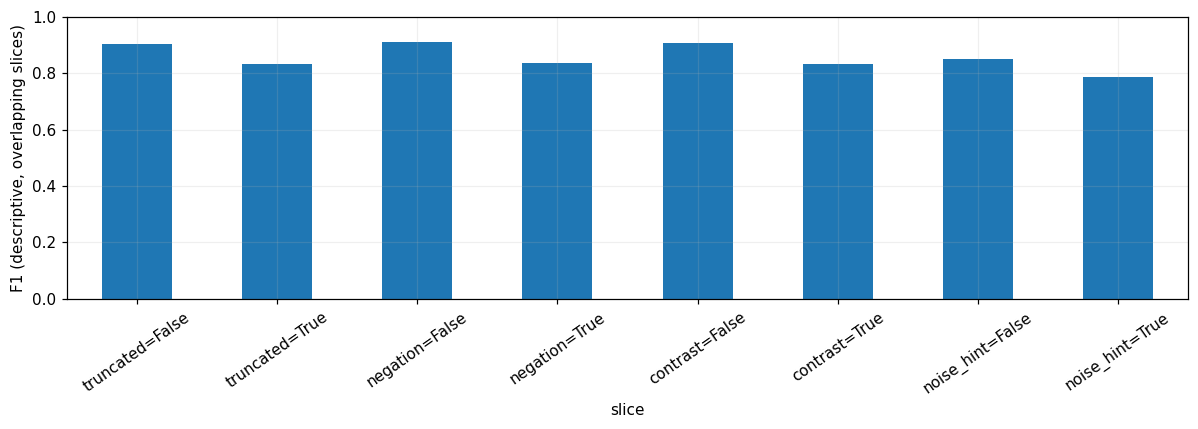

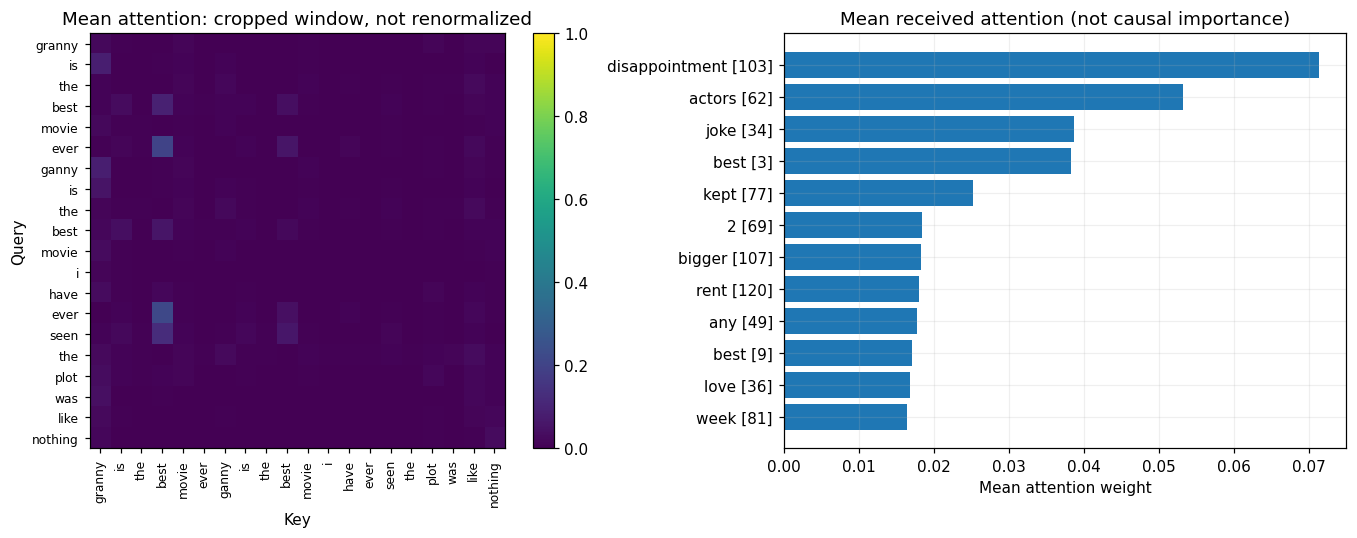

In [17]:
slice_rows = []
for feature in ["truncated", "negation", "contrast", "noise_hint"]:
    for value, group in analysis.groupby(feature):
        slice_rows.append({"feature": feature, "value": bool(value), "samples": len(group),
                           **compute_metrics(group.label, group.p_positive)})
slice_metrics = table(pd.DataFrame(slice_rows), "error_slices")
slice_metrics.assign(slice=lambda f: f.feature+"="+f.value.astype(str)).set_index("slice")["f1"].plot.bar(
    figsize=(11, 4), ylim=(0, 1), rot=35)
plt.ylabel("F1 (descriptive, overlapping slices)")
savefig("error_slices.png")
# Visualize the first 20 visible tokens of one incorrect example.
wrong = selected.loc[~selected.correct]
case = wrong.iloc[0] if len(wrong) else selected.iloc[0]
tokens, case_weights, case_p = attention_for_text(case.text)
n_show = min(20, len(tokens))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
im = axes[0].imshow(case_weights.mean(0)[:n_show, :n_show], cmap="viridis", vmin=0, vmax=1)
axes[0].set_xticks(range(n_show), tokens[:n_show], rotation=90, fontsize=8)
axes[0].set_yticks(range(n_show), tokens[:n_show], fontsize=8)
axes[0].set(title="Mean attention: cropped window, not renormalized", xlabel="Key", ylabel="Query")
axes[0].grid(False)
fig.colorbar(im, ax=axes[0], fraction=.04)
# Full valid query/key attention, not the cropped window, defines this ranking.
received_mass = case_weights.mean(axis=(0, 1))
top = np.argsort(received_mass)[-12:]
axes[1].barh([f"{tokens[i]} [{i}]" for i in top], received_mass[top])
axes[1].set(title="Mean received attention (not causal importance)", xlabel="Mean attention weight")
savefig("error_analysis_attention.png")

26. Error analysis - nhận xét 3 đúng và 3 sai

P(+) là xác suất dự đoán positive; giới hạn input là 128 token. Các diễn giải nguyên nhân dưới đây là giả thuyết khi đọc văn bản, không phải kết luận nhân quả từ model.

| Mẫu | Nhãn thật → Dự đoán | P(+) | Phân tích |
|---|---|---|---|
| 941 - đúng | Positive → Positive | 0,9908 | “Funny”, “wonderful”, “hilarious” thể hiện lời khen. Các câu chứa “don't” mang tính điều kiện, không phủ định đánh giá chung. Review 115 token, không bị cắt. |
| 27406 - đúng | Negative → Negative | 0,1052 | “Garbage”, “disgusting” là tín hiệu tiêu cực rõ. Review 187 token bị cắt còn 128; phần được giữ vẫn thể hiện thái độ chê phim. Có contrast và lời khen phim khác ở phần sau. |
| 48844 - đúng | Negative → Negative | 0,0238 | Có phủ định và sentiment pha trộn: “not a terrible film”, trẻ em “loved it”, nhưng người viết chê “dull” và ví phim như quảng cáo. Review 111 token, không bị cắt. |
| 29880 - sai | Positive → Negative | 0,2565 | Khen “best movie”, “love this movie” nhưng thất vọng về việc thuê/mua phim. Có thể model nhầm đối tượng của cảm xúc. Review 158 token bị cắt, song lời khen vẫn có trong input nên không thể quy toàn bộ lỗi cho truncation. |
| 19252 - sai | Positive → Negative | 0,1280 | “Painful”, “uncomfortable”, “horrible” mô tả trải nghiệm/nhân vật, trong khi người viết đánh giá cao khả năng phản chiếu người xem. Sentiment gián tiếp có thể bị hiểu theo nghĩa tiêu cực của từ. Review 116 token, không bị cắt. |
| 47528 - sai | Positive → Negative | 0,4495 | Review 186 token chủ yếu kể nội dung. Lời khuyên “Watch this movie… very nice time” nằm trong phần bị cắt, khiến model thiếu tín hiệu đánh giá tích cực quan trọng. |

Câu hỏi: Các yếu tố rare word, domain-specific term và noise xuất hiện thế nào?
Trả lời: “Bionicle”, “Chekhov”, “Eramus” và “Ganny” không có trong vocabulary nên thành UNK. “Plot”, “actors”, “animated” là những từ thuộc lĩnh vực phim cần hiểu theo ngữ cảnh. Mẫu 29880 có lỗi chính tả, viết hoa và địa chỉ email; chưa đủ bằng chứng khẳng định riêng yếu tố nào gây lỗi.

Câu hỏi: Các token quan trọng có xuất hiện trong attention pattern không?
Trả lời: Có trong biểu đồ mẫu 29880: “best”, “love”, “disappointment” đều thuộc nhóm nhận nhiều attention trung bình; “disappointment” cao nhất. Biểu đồ heatmap bên trái chỉ hiển thị 20 token đầu; biểu đồ xếp hạng bên phải dùng toàn bộ input đã giữ lại.

Câu hỏi: Phân biệt model behavior và human interpretation thế nào?
Trả lời: Model behavior là dự đoán negative và phân phối weights quan sát được. Human interpretation là giả thuyết model nhầm sự thất vọng về thuê phim với chất lượng phim. Attention không chứng minh nguyên nhân quyết định; cần thêm kiểm tra như thay/xóa token có kiểm soát để đánh giá giả thuyết.

28. Prediction verification — Kiểm chứng Prediction 6: tốc độ theo độ dài

Dự đoán ban đầu: Transformer không luôn nhanh hơn RNN trên mọi sequence length.

Đo Transformer và LSTM tại T=8,16,32,64,128,256, cùng batch đánh giá, d_model=128, thiết bị và số threads.
Lấy cùng các review train có ít nhất 256 token, cắt về từng T để hai model có đúng cùng input và không có PAD.
Đo riêng inference và một training step (forward + backward + clipping + Adam), warm-up 2 bước,
5 lần lặp × 2 bước; báo median và khoảng tứ phân vị. Thứ tự hai model được đảo qua các lần đo.

Cell dùng model mới trong phạm vi hàm, không cập nhật các model đã huấn luyện/checkpoint. Không cần train lại
10 epochs. Dữ liệu đã ở thiết bị trước khi tính giờ; không tính tokenize, DataLoader, validation hay lưu file.
Đây là benchmark chi phí tính toán, khác với tổng training_seconds ở Experiment 4.

Kết luận được sinh từ số đo: chỉ ghi có phản ví dụ nếu Transformer chậm hơn với hai khoảng tứ phân vị
không chồng nhau. Nếu không, ghi chưa đủ kiểm chứng; không ép kết quả theo dự đoán.
Chạy cell sau các cell cấu hình, dữ liệu và định nghĩa model; có thể chạy trực tiếp khi kernel còn các biến đó.


Prediction 6 benchmark: T=8 completed
Prediction 6 benchmark: T=16 completed
Prediction 6 benchmark: T=32 completed
Prediction 6 benchmark: T=64 completed
Prediction 6 benchmark: T=128 completed
Prediction 6 benchmark: T=256 completed


,mode,length,lstm_ms,transformer_ms,lstm_over_transformer,faster_model
0,inference,8,12.4342,7.1066,1.7496,Transformer
1,inference,16,30.0267,16.0548,1.8703,Transformer
2,inference,32,43.9347,15.3436,2.8634,Transformer
3,inference,64,92.2819,40.3267,2.2884,Transformer
4,inference,128,146.3729,81.2935,1.8005,Transformer
5,inference,256,371.8836,183.7922,2.0234,Transformer
6,train_step,8,69.1541,50.4226,1.3715,Transformer
7,train_step,16,96.1333,82.4886,1.1654,Transformer
8,train_step,32,180.6061,98.9368,1.8255,Transformer
9,train_step,64,442.5629,137.0176,3.2300,Transformer


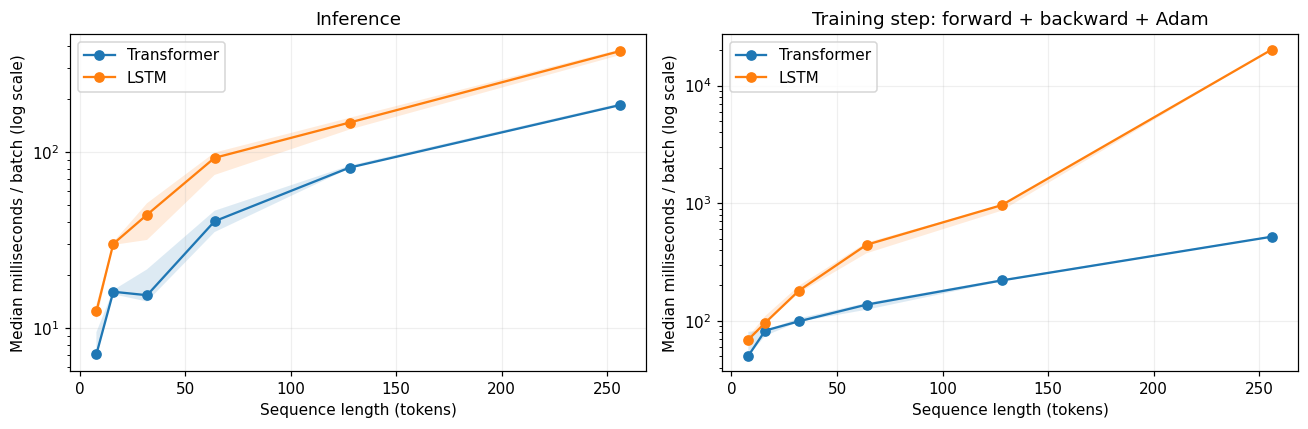

Prediction 6: Chưa tìm thấy phản ví dụ rõ ràng trên thiết bị và cấu hình đã thử. Kết quả chưa đủ kiểm chứng dự đoán 'Transformer không luôn nhanh hơn RNN'; cũng không chứng minh Transformer luôn nhanh hơn trên mọi độ dài/phần cứng.

231

In [18]:
# prediction6_speed_benchmark
# Run after the setup, dataset and model-definition cells; no checkpoint/training run is required.
P6_LENGTHS = [8, 16, 32, 64, 128, 256]
P6_REPEATS, P6_STEPS, P6_WARMUP = 5, 2, 2

def benchmark_prediction6():
    # Local fresh models: do not update the trained models or their checkpoints.
    long_indices = [i for i, seq in enumerate(encoded["train"]) if len(seq) >= max(P6_LENGTHS)]
    batch_size = min(BATCH_SIZE, len(long_indices))
    if batch_size < 2:
        raise ValueError("Need at least two training reviews with >=256 tokens")
    indices = long_indices[:batch_size]
    target = torch.tensor(labels["train"][indices], dtype=torch.float32, device=DEVICE)
    loss_function = nn.BCEWithLogitsLoss()
    measured = []
    cuda_devices = [DEVICE.index if DEVICE.index is not None else torch.cuda.current_device()] if DEVICE.type == "cuda" else []

    with torch.random.fork_rng(devices=cuda_devices):
        for length in P6_LENGTHS:
            ids = torch.tensor([encoded["train"][i][:length] for i in indices], device=DEVICE)
            for mode in ["inference", "train_step"]:
                models, optimizers = {}, {}
                for architecture in ["Transformer", "LSTM"]:
                    torch.manual_seed(SEED)
                    spec = Spec(architecture=architecture, max_length=length,
                                pooling="last_hidden" if architecture == "LSTM" else "mean",
                                use_pe=(architecture == "Transformer"))
                    model = make_model(spec)
                    model.train(mode == "train_step")
                    models[architecture] = model
                    if mode == "train_step":
                        optimizers[architecture] = torch.optim.Adam(model.parameters(), lr=LR)

                def step(architecture):
                    model = models[architecture]
                    if mode == "inference":
                        with torch.inference_mode():
                            model(ids)
                    else:
                        optimizer = optimizers[architecture]
                        optimizer.zero_grad(set_to_none=True)
                        loss = loss_function(model(ids), target)
                        loss.backward()
                        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                        optimizer.step()

                for architecture in models:
                    for _ in range(P6_WARMUP):
                        step(architecture)
                sync_device()
                samples = {name: [] for name in models}
                # Alternate order to reduce systematic first/second-model timing bias.
                for repeat in range(P6_REPEATS):
                    order = ["Transformer", "LSTM"] if repeat % 2 == 0 else ["LSTM", "Transformer"]
                    for architecture in order:
                        sync_device()
                        started = time.perf_counter()
                        for _ in range(P6_STEPS):
                            step(architecture)
                        sync_device()
                        elapsed_ms = 1000 * (time.perf_counter() - started) / P6_STEPS
                        samples[architecture].append(elapsed_ms)
                for architecture, timings in samples.items():
                    measured.append({"architecture": architecture, "mode": mode, "length": length,
                                     "batch_size": batch_size, "median_ms": float(np.median(timings)),
                                     "q25_ms": float(np.percentile(timings, 25)),
                                     "q75_ms": float(np.percentile(timings, 75)),
                                     "repeats": P6_REPEATS, "steps_per_repeat": P6_STEPS,
                                     "device": str(DEVICE), "torch_version": torch.__version__})
                del step, models, optimizers, model
                if DEVICE.type == "cuda":
                    torch.cuda.empty_cache()
            print(f"Prediction 6 benchmark: T={length} completed", flush=True)
    return pd.DataFrame(measured)

prediction6_timings = benchmark_prediction6()
prediction6_timings.to_csv(OUT / "prediction6_speed_details.csv", index=False, encoding="utf-8-sig")
prediction6_speed = prediction6_timings.pivot(index=["mode", "length"], columns="architecture", values="median_ms").reset_index()
prediction6_speed.columns.name = None
prediction6_speed = prediction6_speed.rename(columns={"Transformer": "transformer_ms", "LSTM": "lstm_ms"})
prediction6_speed["lstm_over_transformer"] = prediction6_speed.lstm_ms / prediction6_speed.transformer_ms
prediction6_speed["faster_model"] = np.where(prediction6_speed.transformer_ms < prediction6_speed.lstm_ms,
                                             "Transformer", "LSTM")
table(prediction6_speed, "prediction6_speed")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, mode in zip(axes, ["inference", "train_step"]):
    for architecture in ["Transformer", "LSTM"]:
        part = prediction6_timings[(prediction6_timings["mode"] == mode) &
                                   (prediction6_timings.architecture == architecture)].sort_values("length")
        ax.plot(part.length, part.median_ms, "o-", label=architecture)
        ax.fill_between(part.length, part.q25_ms, part.q75_ms, alpha=0.15)
    ax.set(xlabel="Sequence length (tokens)", ylabel="Median milliseconds / batch (log scale)",
           title="Inference" if mode == "inference" else "Training step: forward + backward + Adam")
    ax.set_yscale("log")
    ax.legend()
savefig("prediction6_speed.png")

# A counterexample is reported only when the interquartile timing bands are separated.
p6_transformer = prediction6_timings[prediction6_timings.architecture == "Transformer"].set_index(["mode", "length"])
p6_lstm = prediction6_timings[prediction6_timings.architecture == "LSTM"].set_index(["mode", "length"])
p6_slower = p6_transformer.q25_ms > p6_lstm.q75_ms
if p6_slower.any():
    p6_cases = ", ".join(f"{mode}, T={length}" for mode, length in p6_slower[p6_slower].index)
    prediction6_conclusion = (
        "Prediction 6: Đúng trong phạm vi benchmark. Transformer chậm hơn LSTM ở " + p6_cases +
        ". Kết quả là phản ví dụ cho phát biểu 'Transformer luôn nhanh hơn RNN', "
        "với LSTM là một biến thể RNN. Không khái quát thứ hạng sang phần cứng khác."
    )
else:
    prediction6_conclusion = (
        "Prediction 6: Chưa tìm thấy phản ví dụ rõ ràng trên thiết bị và cấu hình đã thử. "
        "Kết quả chưa đủ kiểm chứng dự đoán 'Transformer không luôn nhanh hơn RNN'; "
        "cũng không chứng minh Transformer luôn nhanh hơn trên mọi độ dài/phần cứng."
    )
display(Markdown(prediction6_conclusion))
(OUT / "prediction6_conclusion.txt").write_text(prediction6_conclusion, encoding="utf-8")


28. Prediction verification - đối chiếu sáu dự đoán ban đầu

| Prediction | Dự đoán | Kết quả | Đúng/Sai | Giải thích |
|---|---|---|---|---|
| 1 | Transformer xử lý token song song hơn RNN. | T=128: Transformer 1419.12 giây, LSTM 4679.79 giây. | Đúng | Self-attention xử lý đồng thời các vị trí; phép đo thời gian hỗ trợ nhận xét trong cấu hình đang thử. |
| 2 | Không PE thì không biết thứ tự token nếu không có nguồn vị trí khác. | Không có dự đoán nào đổi khi shuffle model không PE. | Đúng | Self-attention không tự mang thông tin vị trí. |
| 3 | Không PE và dùng mean pooling thì không phân biệt được câu cùng token, khác thứ tự. | Khoảng cách mean pooling trong toy experiment xấp xỉ 0. | Đúng | Hoán vị token không đổi kết quả mean pooling. |
| 4 | Các heads không nhất thiết học cùng pattern. | Entropy khác nhau, từ 0,3919 đến 0,6599. | Đúng | Các heads có phân phối attention khác nhau trên câu được kiểm tra. |
| 5 | Tăng heads không bảo đảm accuracy tăng. | Tăng từ 4 lên 8 heads: accuracy 84.63% → 83.90%. | Đúng | Thêm heads không bảo đảm học representation phù hợp hơn. |
| 6 | Transformer không luôn nhanh hơn RNN ở mọi độ dài. | Transformer nhanh hơn LSTM tại cả 6 độ dài 8-256, ở inference và training step. | Chưa đủ kiểm chứng | Chưa tìm được phản ví dụ trên CPU/cấu hình đã thử; không đại diện mọi độ dài và phần cứng. |

Không có prediction nào được xác định là sai từ kết quả hiện có. Prediction 6 chưa được xác nhận, không đổi dự đoán ban đầu để khớp kết quả và không xem kết quả một thiết bị là bằng chứng cho mọi trường hợp.

7. Tổng hợp, xuất kết quả và câu hỏi diễn giải
Các bảng và hình được tạo từ số đo thật của lần chạy hiện tại. Một lần chạy chưa đủ kết luận
tăng heads/length/CLS luôn cải thiện. Validation loss tăng trong khi train loss giảm là dấu hiệu
cần xem xét overfitting; hai losses cao có thể gợi ý thiếu train hoặc model chưa phù hợp.
Đọc kèm số epochs, tỷ lệ token giữ lại, số mẫu và chi phí; không dùng attention làm explanation.

In [19]:
result_frames = {
    "positional_toy": pe_results, "heads": heads_test, "head_diversity": diversity_table,
    "architecture": architecture_test, "sequence_length": length_results.merge(
        length_test[["run_id", "test_accuracy", "test_precision", "test_recall", "test_f1"]], on="run_id"),
    "pooling": pooling_test, "all_models": test_results, "word_order": shuffle_results,
    "application": application, "error_slices": slice_metrics
}
results = pd.concat([frame.assign(experiment=name, mode=RUN_MODE, seed=SEED)
                     for name, frame in result_frames.items()], ignore_index=True, sort=False)
results.to_csv(OUT / "results.csv", index=False, encoding="utf-8-sig")
environment.update({"vocabulary": len(vocab), "split_samples": {k: len(v) for k, v in splits.items()},
                    "data_hash": data_hash, "source_hash": source_hash,
                    "selection": "minimum validation loss; fixed 0.5 threshold; fixed reference model"})
(OUT / "run_config.json").write_text(json.dumps(environment, indent=2), encoding="utf-8")
ref = model_runs[REFERENCE]
torch.save(ref["model"].state_dict(), OUT / "transformer_reference.pt")
(OUT / "reference_spec.json").write_text(json.dumps(asdict(REFERENCE), indent=2), encoding="utf-8")

notes = [
    f"Mode={RUN_MODE}; samples={environment['split_samples']}; epochs={EPOCHS}; seed={SEED}.",
    f"Reference test accuracy={reference_test['accuracy']:.4f}, F1={reference_test['f1']:.4f}.",
    f"Reference checkpoint epoch={ref['row']['best_epoch']}; validation loss={ref['row']['validation_loss']:.4f}.",
    "Fixed reference: Transformer 4 heads, 128 content tokens, PE, masked mean pooling.",
    "No-PE permutation invariance checked on toy and trained classifier; accuracy is measured separately.",
    "Attention entropy and similarity describe one input, not linguistic head identities or causal explanations.",
    "Error flags are heuristic; human interpretation is left blank for manual review.",
    "Full training is required for a full-dataset report when current mode is quick.",
    "Single-seed results; repeat multiple seeds before claiming a robust ranking."
]
(OUT / "observations.txt").write_text("\n".join(notes), encoding="utf-8")
display(Markdown("\n\n".join(notes)))
print("Exported", len(list(OUT.glob('*.csv'))), "CSV tables and", len(list(OUT.glob('*.png'))), "figures to", OUT)
display(pd.DataFrame({"file": sorted(p.name for p in OUT.iterdir() if p.is_file())}))

Mode=full; samples={'train': 29746, 'validation': 9916, 'test': 9916}; epochs=10; seed=2026.

Reference test accuracy=0.8463, F1=0.8509.

Reference checkpoint epoch=3; validation loss=0.3746.

Fixed reference: Transformer 4 heads, 128 content tokens, PE, masked mean pooling.

No-PE permutation invariance checked on toy and trained classifier; accuracy is measured separately.

Attention entropy and similarity describe one input, not linguistic head identities or causal explanations.

Error flags are heuristic; human interpretation is left blank for manual review.

Full training is required for a full-dataset report when current mode is quick.

Single-seed results; repeat multiple seeds before claiming a robust ranking.

Exported 47 CSV tables and 17 figures to D:\Study\Study_Class\Semester_7\NLP\Lab\lab07\outputs\full


,file
0,all_learning_history.csv
1,all_models_test.csv
2,application_predictions.csv
3,application_predictions.png
4,architecture_learning_history.csv
...,...
65,transformer_reference.pt
66,transformer_vs_lstm.png
67,vocab.json
68,word_order_test.csv


27. So sánh LAB 04 → LAB 07 và câu hỏi tổng hợp

Câu hỏi: Mỗi bước đã giải quyết limitation nào của bước trước và còn hạn chế gì?

| Biểu diễn / mô hình | Cải thiện | Hạn chế còn lại |
|---|---|---|
| TF-IDF | Biểu diễn văn bản bằng trọng số từ để so sánh/phân loại. | Sparse, ngữ nghĩa và thứ tự hạn chế; n-gram chỉ bổ sung thứ tự cục bộ. |
| Word2Vec / average Word2Vec | Vector dense biểu diễn quan hệ ngữ nghĩa giữa từ. | Embedding tĩnh; lấy trung bình mất thứ tự và ngữ cảnh từng câu. |
| LSTM | Biểu diễn theo ngữ cảnh và thứ tự qua hidden state. | Xử lý tuần tự, thông tin xa có thể khó giữ qua nhiều bước. |
| Attention | Tổng hợp trực tiếp thông tin từ các vị trí liên quan, giảm phụ thuộc vào một vector nén cuối. | Chưa tự cung cấp vị trí hoặc một encoder hoàn chỉnh; attention gắn RNN vẫn có phần tuần tự. |
| Transformer | Kết hợp multi-head attention, PE, FFN và residual/norm; hỗ trợ tương tác trực tiếp và song song. | Attention chuẩn tốn O(T²), cần thông tin vị trí, dữ liệu và tài nguyên; vẫn có truncation và lỗi ngữ cảnh. |

Mạch nối LAB 01-07: TF-IDF và tìm kiếm tương đồng → mô hình xác suất n-gram → embedding ngữ nghĩa → phân loại → recurrent sequence modeling → attention → Transformer. Mỗi bước bổ sung cách biểu diễn hoặc xử lý context; các phương pháp trước vẫn có giá trị tùy bài toán và tài nguyên.

29. Câu hỏi và nhận xét learning curves

Câu hỏi: Có dấu hiệu overfitting, underfitting, hội tụ hay instability không?
Trả lời: Transformer có validation loss thấp nhất ở epoch 3 (0,3746), LSTM ở epoch 5 (0,4082). Sau đó train loss tiếp tục giảm nhưng validation loss tăng, cho thấy overfitting. Không có bằng chứng underfitting nổi bật ở cuối quá trình; loss hữu hạn và không có lỗi số học được báo. Validation dao động, chưa thể quy riêng cho bất ổn tối ưu hóa.

Câu hỏi: Vì sao không lấy checkpoint ở epoch cuối?
Trả lời: Epoch cuối có train loss thấp hơn nhưng validation loss xấu hơn. Chọn checkpoint bằng validation loss giúp đánh giá khả năng tổng quát hóa, không chọn dựa trên test.

31. Individual learning check - câu hỏi tự ôn

| Câu hỏi | Trả lời ngắn |
|---|---|
| Vì sao Transformer cần PE? | Để cung cấp thông tin thứ tự/vị trí mà self-attention tự thân không có. |
| Multi-head khác single-head ở đâu? | Nhiều phép chiếu attention được học song song, ghép kết quả rồi chiếu qua W_O. |
| d_model=128, 8 heads thì d_k bằng bao nhiêu? | 16. |
| Vì sao scores là T × T? | T query được so với T key trong mỗi head. |
| Residual có vai trò gì? | Giữ đường truyền trực tiếp của input và gradient, hỗ trợ tối ưu hóa. |
| FFN làm gì? | Biến đổi phi tuyến feature tại từng token bằng cùng bộ trọng số. |
| Vì sao song song hơn RNN? | Các vị trí không phải chờ hidden state của bước trước trong self-attention. |
| Sequence dài gấp đôi thì scores thay đổi thế nào? | Số phần tử tăng gấp 4 nếu batch và số heads giữ nguyên. |
| Attention cao có chứng minh token gây ra dự đoán không? | Không; đó là phân phối trọng số nội bộ, không phải bằng chứng nhân quả. |

Reflection và chuyển sang LAB 08

Qua LAB 07, em hiểu cách ghép attention, FFN, residual và LayerNorm thành Transformer Encoder, cùng vai trò của PE trong biểu diễn thứ tự. Thực nghiệm cho thấy tăng heads không bảo đảm tăng accuracy; tăng length giữ thêm ngữ cảnh nhưng tốn chi phí T². Phân tích lỗi cho thấy model còn khó xử lý sentiment gián tiếp, đối tượng của cảm xúc và review bị cắt mất lời đánh giá.

Transformer hỗ trợ tương tác trực tiếp và xử lý song song, nhưng vẫn phụ thuộc cấu hình, dữ liệu và tài nguyên. Attention visualization giúp quan sát phân phối trọng số, không thay thế giải thích nhân quả. Một seed chưa đủ kết luận cấu hình luôn tốt nhất.

Câu hỏi: Vì sao LAB 08 chuyển sang pretrained Transformer/BERT rồi fine-tune?
Trả lời: Pretraining trên lượng văn bản lớn giúp học representation ngôn ngữ có thể tái sử dụng; fine-tuning điều chỉnh representation cho task cụ thể, thay vì học toàn bộ từ đầu trên dataset phân loại nhỏ. Vẫn cần kiểm soát chi phí, độ dài, domain và đánh giá độc lập.

AI assistance statement

Tool: Codex.
Purpose: hỗ trợ triển khai/debug pipeline, đối chiếu câu hỏi và soạn phần trình bày từ kết quả đã lưu.
Generated: code ban đầu, benchmark prediction 6 và các bản nháp Markdown bổ sung.
Modified: người học đã chạy lại notebook; nội dung bổ sung hiện dựa trên output full đã lưu.
Verified: kiểm tra dữ liệu số được trích dẫn, cấu trúc notebook và bảo toàn code/output hiện có; người học đọc lại và xác nhận các diễn giải trước khi nộp.